# Init

In [1]:
import numpy as np
import pandas as pd
import h5py
import os
import sys

import matplotlib.pyplot as plt

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits, ascii

from scipy import stats
from scipy.stats import gaussian_kde

In [2]:
from astropy.cosmology import FlatLambdaCDM 
from astropy.cosmology import z_at_value
cosmo = FlatLambdaCDM(H0 = 70, Om0 = 0.3)

In [3]:
"""
plot_style.py
-------------
Master matplotlib/plotly style loader.
Usage:
    from plot_style import *
    from plot_style import get_n_colors, MidFactor
"""

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import FuncFormatter, ScalarFormatter, LogLocator
from matplotlib.colors import to_rgba
from matplotlib.gridspec import GridSpec
import matplotlib.patheffects as path_effects
import plotly.graph_objects as go
from matplotlib.lines import Line2D
import matplotlib.patches as Patches
from matplotlib.legend_handler import HandlerTuple
import matplotlib.patheffects as pe
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ── RC Params ─────────────────────────────────────────────────────────────────
params = {
        # Font
        "font.family":          "serif",
        "font.size":            24,
        "text.usetex":          True,

        # Tick labels
        "xtick.labelsize":      20,
        "ytick.labelsize":      20,

        # Tick direction & size
        "xtick.direction":      "in",
        "ytick.direction":      "in",
        "xtick.major.size":     7,
        "ytick.major.size":     7,
        "xtick.minor.size":     3.5,
        "ytick.minor.size":     3.5,
        "xtick.minor.visible":  False,
        "ytick.minor.visible":  False,

        # Tick padding & axes
        "xtick.major.pad":      7,
        "axes.linewidth":       2.0,

        # tight layout
        "figure.constrained_layout.use": True
    }

plt.rcParams.update(params)


In [4]:
# ── Helpers ───────────────────────────────────────────────────────────────────

# Source - https://stackoverflow.com/a/49601444
# Posted by Ian Hincks, modified by community. See post 'Timeline' for change history
# Retrieved 2026-07-08, License - CC BY-SA 4.0

def lighten_color(color, amount=0.5):
    """
    Lightens the given color by multiplying (1-luminosity) by the given amount.
    Input can be matplotlib color string, hex string, or RGB tuple.

    Examples:
    >> lighten_color('g', 0.3)
    >> lighten_color('#F034A3', 0.6)
    >> lighten_color((.3,.55,.1), 0.5)
    """
    import matplotlib.colors as mc
    import colorsys
    try:
        c = mc.cnames[color]
    except:
        c = color
    c = colorsys.rgb_to_hls(*mc.to_rgb(c))
    return colorsys.hls_to_rgb(c[0], 1 - amount * (1 - c[1]), c[2])

def get_n_colors(n, cmap_name="viridis"):
    """Sample n evenly-spaced colours from a matplotlib colormap."""
    cmap = plt.get_cmap(cmap_name)
    return [cmap(i / max(n - 1, 1)) for i in range(n)]


def MidFactor(n):
    """Return the middle divisor of n (useful for subplot grid layout)."""
    divisors = [i for i in range(1, n + 1) if n % i == 0]
    return divisors[len(divisors) // 2]

# Arrow plot
import matplotlib.path as mpath
def up_arrow_marker():
    Path = mpath.Path
    verts = [
        (0.0, 0.0),        
        (-0.03, 0.0),      
        (-0.28, -0.27),     
        (-0.21, -0.35),    
        (-0.06, -0.2), 
        (-0.06, -1.0),
        (0.06, -1.0),
        (0.06, -0.2), 
        (0.21, -0.35),
        (0.28, -0.27),
        (0.03, 0.0),
        (0.0, 0.0)
    ]
    codes = [Path.MOVETO] + [Path.LINETO]*10 + [Path.CLOSEPOLY]
    return Path(verts, codes)

def down_arrow_marker():
    Path = mpath.Path
    verts = [
        (0.0, 0.0),        # Tip
        (-0.3, 0.3),       # Left of arrowhead
        (-0.05, 0.3),      # Left shaft edge
        (-0.05, 1.0),      # Shaft top left
        (0.05, 1.0),       # Shaft top right
        (0.05, 0.3),       # Right shaft edge
        (0.3, 0.3),        # Right of arrowhead
        (0.0, 0.0),        # Close shape at tip
    ]
    codes = [mpath.Path.MOVETO] + [mpath.Path.LINETO]*6 + [mpath.Path.CLOSEPOLY]

    verts = [
        (0.0, 0.0),        
        (-0.03, 0.0),      
        (-0.28, 0.27),     
        (-0.21, 0.35),    
        (-0.06, 0.2), 
        (-0.06, 1.0),
        (0.06, 1.0),
        (0.06, 0.2), 
        (0.21, 0.35),
        (0.28, 0.27),
        (0.03, 0.0),
        (0.0, 0.0)
    ]
    codes = [Path.MOVETO] + [Path.LINETO]*10 + [Path.CLOSEPOLY]
    
    return Path(verts, codes)

up_arrow_marker = up_arrow_marker()
down_arrow_marker = down_arrow_marker()

grid_alpha = 0.1
grid_color = 'grey'
grid_ls = "-"

# Load in things

In [39]:
h5file = "/Users/jordan/Documents/JWST-MIRI-AGN/data/analysis_data.h5"
filters_info = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/throughputs/wavelengths.txt", delimiter=" ")

In [40]:
# number counts 
smiles_number_counts = pd.read_hdf(h5file, "number_counts/smiles")
midis_number_counts = pd.read_hdf(h5file, "number_counts/midis")

smiles_frame_stats = pd.read_hdf(h5file, "frame_stats/smiles")
midis_frame_stats = pd.read_hdf(h5file, "frame_stats/midis")


prospect_stellar = pd.read_hdf(h5file, "ProSpect/Stellar")
prospect_stellarAGN = pd.read_hdf(h5file, "ProSpect/StellarAGN")
prospect_robust = pd.read_hdf(h5file, "ProSpect/Robust")
prospect_robustDIC = pd.read_hdf(h5file, "ProSpect/RobustDIC")


photoz = pd.read_hdf(h5file, "photoz/photoz")

SMBH_results = pd.read_hdf(h5file, "SMBH/SMBH")

In [41]:
"""Get redshift sample"""

# lbt_bins = np.arange(8.0, 13.5, 0.5)
lbt_bins = np.append(np.arange(8.0, 13.0, 0.5), [13])
lbt_mids = lbt_bins[:-1] + np.diff(lbt_bins)/2.0

zbins = z_at_value(cosmo.lookback_time, lbt_bins*u.Gyr).value
# zbins = np.append(z_at_value(cosmo.lookback_time, lbt_bins*u.Gyr).value, [7,9,11])
zmids = zbins[:-1] + np.diff(zbins)/2.0

sample_idx = (prospect_robust['zQ50'] >= zbins[0]) & (prospect_robust['zQ50'] < zbins[-1])
quenched_idx = prospect_robust["SFR10Q50"][sample_idx]/prospect_robust["StellarMassQ50"][sample_idx] <= 0.2/(1e9*cosmo.age(prospect_robust["zQ50"][sample_idx]).value) # probably just use this for upper limits on the SFR10 plots 

prospect_sample = prospect_robust[sample_idx]
SMBH_results_sample = SMBH_results[sample_idx]

sampleDIC_idx = (prospect_robustDIC['zQ50'] >= zbins[0]) & (prospect_robustDIC['zQ50'] < zbins[-1])
prospect_sampleDIC = prospect_robustDIC[sample_idx]

starforming_sample = prospect_robust[sample_idx][~quenched_idx] 
quenched_sample = prospect_robust[sample_idx][quenched_idx] # for upper limits
minimum_SFR10_vals = quenched_sample["StellarMassQ50"] * 0.2/(1e9*cosmo.age(quenched_sample["zQ50"]).value)

# constants 
LAGN2BHAR = ( 3.154e7 * 1e-7 * (0.1 * 3e8**2)**-1 / 2e30)

# Number counts

In [8]:
stone25 = pd.read_csv(
    os.path.expanduser("~/Documents/JWST-MIRI-AGN/data/literature/number_counts/stone25.csv")
)

In [ ]:
MIRI_keys = ["F560W", "F770W", "F1000W", "F1280W", "F1500W", "F1800W", "F2100W", "F2550W"]
cols = [
  "#2166AC",  # deep blue
  "#4393C3",  # mid blue
  "#92C5DE",  # light blue
  "#EDF176",  # pale yellow-orange
  "#F4A736",  # yellow-orange
  "#E8601C",  # orange
  "#D6301F",  # red-orange
  "#A50026"   # deep red
]
cols = ("#08519C", "#3182BD", "#6BAED6", "#807DBA",
          "#984EA3", "#C0357A", "#DE2D26", "#A50026")

fig, ax = plt.subplots(ncols=2, nrows = 4, sharex = True, sharey = True, figsize = (10,8))
ax = ax.flatten()

fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

for i, axx in enumerate(ax):
    axx.errorbar(
        smiles_number_counts["uJy_mids"],
        smiles_number_counts[f"{MIRI_keys[i]}_cumul"],
        yerr = smiles_number_counts[f"{MIRI_keys[i]}_cumulerr"],
        capsize = 3,
        fmt = "o",
        markersize = 8,
        markeredgecolor = "black",
        markerfacecolor = cols[i],
        ecolor = cols[i],
        alpha = 0.7, 
        label = "SMILES"
    )
    axx.axvline(
        smiles_frame_stats[f"{MIRI_keys[i]}_5sigma_depth_32asec"].values/1e-6,
        color = cols[i],
        ls = "--"
    )
    if i < 2:
        axx.errorbar(
            midis_number_counts["uJy_mids"],
            midis_number_counts[f"{MIRI_keys[i]}_cumul"],
            yerr = midis_number_counts[f"{MIRI_keys[i]}_cumulerr"],
            capsize = 3,
            fmt = "*",
            markersize = 12,
            markerfacecolor = lighten_color(cols[i], amount= 0.5) ,
            markeredgecolor = "black",
            ecolor = cols[i],
            alpha = 0.7,
            label = "MIDIS"
        )
        axx.axvline(
            midis_frame_stats[f"{MIRI_keys[i]}_5sigma_depth_32asec"].values/1e-6,
            color = cols[i],
            ls = ":"
        )

    if i == 1:
        axx.fill_between(
        # -2.5*np.log10(stone25["Flux_uJy"])+23.9,
        stone25["Flux_uJy"],
        stone25[f"{MIRI_keys[i]}_SMILES"] - stone25[f"{MIRI_keys[i]}_SMILES_err"],
        stone25[f"{MIRI_keys[i]}_SMILES"] + stone25[f"{MIRI_keys[i]}_SMILES_err"],
        facecolor = "none",
        hatch = "///",
        edgecolor = "black",
        alpha = 0.8,
        lw = 2
    )
    else:
        axx.fill_between(
            # -2.5*np.log10(stone25["Flux_uJy"])+23.9,
            stone25["Flux_uJy"],
            stone25[f"{MIRI_keys[i]}"] - stone25[f"{MIRI_keys[i]}_err"],
            stone25[f"{MIRI_keys[i]}"] + stone25[f"{MIRI_keys[i]}_err"],
            facecolor = "none",
            hatch = "///",
            edgecolor = "black",
            alpha = 0.8,
            lw = 2,
            label = "Stone+24"
        )
    axx.text(
        0.6,
        0.8,
        MIRI_keys[i],
        transform = axx.transAxes,
        color = cols[i]
        # path_effects = [pe.Stroke(linewidth=2, foreground='black'), pe.Normal()]
    )

ax[0].legend(
    frameon = True,
    fontsize = 18,
    loc = "lower left"
)
ax[0].set_xscale("log")
ax[0].set_yscale("log")

# ax[0].set_xlim([29, 15])
ax[0].set_xlim([4e-3, 2e3])
ax[0].set_ylim([9e-3, 5e2])

# ax[0].set_xticks([28, 24, 20, 16])
ax[0].set_xticks([1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3])
ax[0].set_yticks([1e-1, 1e0, 1e1, 1e2])

fig.supxlabel(r"$\mathrm{S_{\nu} \, [\mu Jy}]$")
fig.supylabel(r"$\mathrm{N(>S_{\nu}) \, [arcmin^{-2}]}$")

plt.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/number_counts.pdf", 
    bbox_inches="tight", 
    dpi = 240
)


In [ ]:
print(f"{-2.5*np.log10(smiles_frame_stats[f"F560W_5sigma_depth_32asec"].values
/midis_frame_stats[f"F560W_5sigma_depth_32asec"].values)} that many mags deeper in F560W")

print(f"{-2.5*np.log10(smiles_frame_stats[f"F770W_5sigma_depth_32asec"].values
/midis_frame_stats[f"F770W_5sigma_depth_32asec"].values)} that many mags deeper in F770W")


# Compare EAZY specz and photoz

In [41]:
def compute_sigmaNMAD(zspec, zphot, zphot_lim=-2):
    zspec = np.array(zspec)
    zphot = np.array(zphot)
    
    # idx = (zphot > zphot_lim) & (~np.isnan(zphot)) & (zspec != -999)
    idx = (~np.isnan(zphot)) & (zspec != -999)

    deltaz = zphot[idx] - zspec[idx]
    
    sigmaNMAD = 1.48 * np.median(np.abs((deltaz - np.median(deltaz)) / (1 + zspec[idx])))
    return sigmaNMAD


def compute_outliers(zspec, zphot, thresh=0.15, zphot_lim=-2):
    zspec = np.array(zspec)
    zphot = np.array(zphot)
    
    # idx = (zphot > zphot_lim) & (~np.isnan(zphot)) & (zspec != -999)
    idx = (~np.isnan(zphot)) & (zspec != -999)
    deltaz = np.abs(zphot[idx] - zspec[idx])
    
    Noutlier = np.sum(deltaz / (1 + zspec[idx]) > thresh)
    outlier_frac = Noutlier / len(zspec[idx])
    
    print(f"Noutlier: {Noutlier}")
    print(f"N total:  {len(zspec[idx])}")
    
    return outlier_frac, deltaz / (1 + zspec[idx]) > thresh

In [44]:
photoz

,zspec,zeazy,zQ50,zQ16,zQ84,z_lo,z_hi,eazyChi2,eazyHessianSD,eazyPz80
0,-999.0000,1.050818,1.059236,1.048831,1.075747,0.010405,0.016511,17.596844,0.015936,0.969306
1,-999.0000,0.131635,NaN,NaN,NaN,NaN,NaN,35.153282,0.013424,0.285717
2,-999.0000,0.249107,0.254225,0.247602,0.258468,0.006623,0.004243,42.682259,0.006884,0.944221
3,-999.0000,0.339199,0.336920,0.334335,0.341134,0.002585,0.004214,32.751446,0.004654,0.998642
4,2.2251,2.417672,NaN,NaN,NaN,NaN,NaN,12.331340,0.043075,0.807555
...,...,...,...,...,...,...,...,...,...,...
6959,-999.0000,36.017826,NaN,NaN,NaN,NaN,NaN,70.693260,0.796853,0.999735
6960,-999.0000,0.091442,NaN,NaN,NaN,NaN,NaN,44.159603,0.011559,0.257054
6961,-999.0000,32.559055,NaN,NaN,NaN,NaN,NaN,20.824306,0.633990,0.521395
6962,-999.0000,1.687645,1.691561,1.617881,1.776208,0.073680,0.084647,34.924191,0.085164,0.689701


[ True False  True ... False  True False]
Noutlier: 32
N total:  540
Noutlier: 31
N total:  540


/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_3993/3998880748.py:10: RuntimeWarning: divide by zero encountered in divide
  sigmaNMAD = 1.48 * np.median(np.abs((deltaz - np.median(deltaz)) / (1 + zspec[idx])))
/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_3993/3998880748.py:22: RuntimeWarning: divide by zero encountered in divide
  Noutlier = np.sum(deltaz / (1 + zspec[idx]) > thresh)
/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_3993/3998880748.py:28: RuntimeWarning: divide by zero encountered in divide
  return outlier_frac, deltaz / (1 + zspec[idx]) > thresh


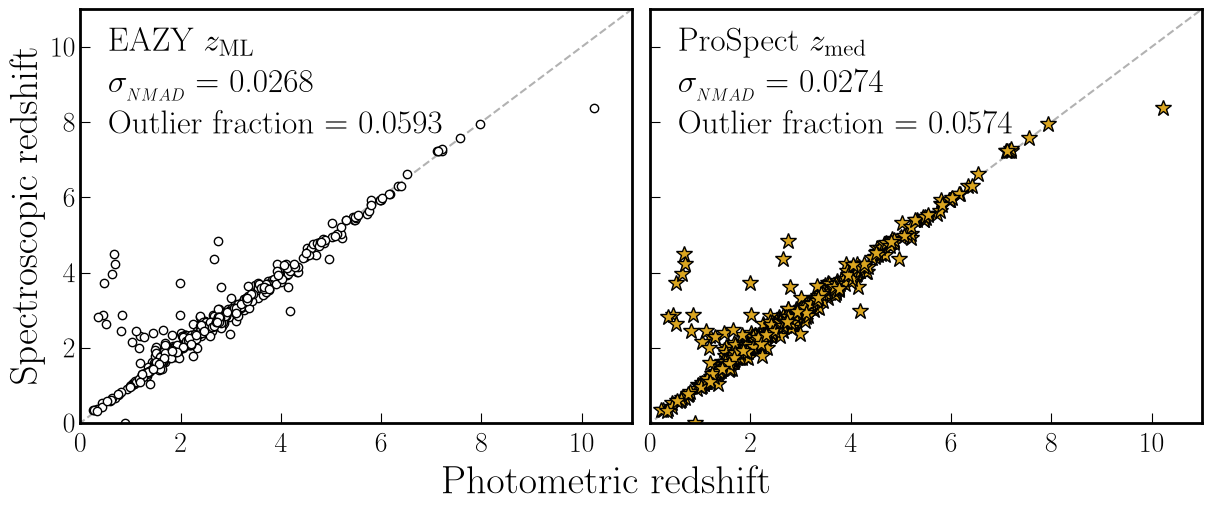

In [47]:
fig, ax = plt.subplots(1,2, figsize = (12,5), layout = "constrained", sharex = True, sharey = True)
# ax = [ax]
# ax[0].scatter(
#     photoz["zeazy"],
#     photoz["zspec"],
#     edgecolor = 'black',
#     facecolor = 'white',
#     s = 50
# )

fit_idx = ~np.isnan(photoz["zQ50"].to_numpy())

zspec = photoz["zspec"][fit_idx]
zeazy = photoz["zeazy"][fit_idx]
zQ50 = photoz["zQ50"][fit_idx]
zhi = photoz["z_hi"][fit_idx]
zlo = photoz["z_lo"][fit_idx]

print(fit_idx)
ax[0].errorbar(
    zeazy,
    zspec,
    # xerr = [photoz["eazyHessianSD"]],
    markersize = 6,
    marker = "o",
    ls = "",
    capsize = 3,
    markeredgecolor = 'black',
    markerfacecolor = 'white',
    ecolor = "black",
    # alpha = 0.6
)
ax[0].text(
    0.05, 0.90, 
    "EAZY $z_{\\mathrm{ML}}$", transform=ax[0].transAxes
)
ax[0].text(
    0.05, 0.80, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=zspec, zphot=zeazy):.4f}", transform=ax[0].transAxes
)
ax[0].text(
    0.05, 0.70, 
    rf"Outlier fraction = {compute_outliers(zspec=zspec, zphot=zeazy)[0]:.4f}", transform=ax[0].transAxes
)

ax[1].errorbar(
    zQ50,
    zspec,
    # xerr = [zlo, zhi],
    markersize = 12,
    marker = "*",
    ls = "",
    capsize = 3,
    markeredgecolor = 'black',
    markerfacecolor = 'goldenrod',
    ecolor = "black",
    # alpha = 0.6
)

ax[1].text(
    0.05, 0.90, 
    "ProSpect $z_{\\mathrm{med}}$", transform=ax[1].transAxes
)
ax[1].text(
    0.05, 0.80, 
    rf"$\sigma_{{_{{NMAD}}}} = $ {compute_sigmaNMAD(zspec=zspec, zphot=zQ50):.4f}", transform=ax[1].transAxes
)
ax[1].text(
    0.05, 0.70, 
    rf"Outlier fraction = {compute_outliers(zspec=zspec, zphot=zQ50)[0]:.4f}", transform=ax[1].transAxes
)

for axx in ax:
    axx.set_xlim([0,11])
    axx.set_ylim([0,11])
    axx.plot(
        [-100,100], 
        [-100, 100],
        ls = "--",
        color = "black", 
        alpha = 0.3
    )
    # ax.set_xlim([zbins[0]-0.5, zbins[-1]+0.5])
    # ax.set_ylim([zbins[0]-0.5, zbins[-1]+0.5])
    # ax.grid(grid_ls, color = grid_color, alpha = grid_alpha)


fig.supxlabel("Photometric redshift")
ax[0].set_ylabel("Spectroscopic redshift", fontsize = 28)

# ax[0].legend(fancybox=True)

fig.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/jades_specz.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


# Compare Literature AGN

In [ ]:
AGN_compare = pd.read_hdf(h5file, "literatureAGN/compare")
# AGN_compare = AGN_compare[AGN_compare["zQ50"] >= zbins[0]]

In [ ]:
fig, ax = plt.subplots(1,1, figsize = (7,5), layout = "constrained")
ax = [ax]

marker_list = ["o", "^", "v"]
survey_list = ["Stemo20", "Scholtz25", "Juodzbalis26"]
survey_label_list = ["Stemo+20", "Scholtz+25", "Juodžbalis+26"]

for i in range(len(survey_list)):
    subset = AGN_compare[AGN_compare["survey"] == survey_list[i]]
    for j, (_, row) in enumerate(subset.iterrows()):
        fittype_ = row["FitType"]
        if row["FitType"] == "StellarAGN":
            facecolor = "tab:red"
        else:
            facecolor = "tab:blue"

        ax[0].errorbar(
            row["AGNlumQ50_lit"],
            row["StellarAGN_AGNlumQ50"],
            xerr = [[row["AGNlum_lo_lit"]], [row["AGNlum_hi_lit"]]],
            yerr = [[row["StellarAGN_AGNlum_lo"]], [row["StellarAGN_AGNlum_hi"]]],
            markersize = 8,
            marker = marker_list[i],
            ls = "",
            capsize = 3,
            markeredgecolor = facecolor,
            markerfacecolor = lighten_color(facecolor, 0.5),
            ecolor = facecolor,
            alpha = 0.7
        )

        # if row["class_from_vadim"] == "LBD":
        #     ax[0].scatter(
        #         row["AGNlumQ50_lit"],
        #         row["StellarAGN_AGNlumQ50"],
        #         # s = 20,
        #         color = "blue"
        #     )
        # elif row["class_from_vadim"] == "LRD":
        #     ax[0].scatter(
        #         row["AGNlumQ50_lit"],
        #         row["StellarAGN_AGNlumQ50"],
        #         # s = 20,
        #         color = "red"
        #     )

ax[0].plot(
    10**np.linspace(35,50,100),
    10**np.linspace(35,50,100),
    ls = "--",
    color = "grey"
)

literature_sources = [
    Line2D([0], [0], marker = marker_list[0], label = survey_label_list[0], color = "grey", ls = "", markersize = 10),
    Line2D([0], [0], marker = marker_list[1], label = survey_label_list[1], color = "grey", ls = "", markersize = 10),
    Line2D([0], [0], marker = marker_list[2], label = survey_label_list[2], color = "grey", ls = "", markersize = 10)
]
lit_leg_ = ax[0].legend(handles=literature_sources, loc='lower left', fontsize = 14)

literature_sources = [
    Line2D([0], [0], marker = "o", label = "Stellar+AGN", color = "tab:red", ls = "", markersize = 10, alpha = 0.7),
    Line2D([0], [0], marker = "o", label = "Stellar", color = "tab:blue", ls = "", markersize = 10, alpha = 0.7)
]
ax[0].legend(handles=literature_sources, loc='upper left', fontsize = 15)
ax[0].add_artist(lit_leg_)

ax[0].set_xscale("log")
ax[0].set_yscale("log")

ax[0].set_xlim([7e41, 4e46])
ax[0].set_ylim([8e34, 4e46])

ax[0].set_xlabel(r"$\mathrm{L_{AGN} - Literature \, [erg \, s^{-1}]}$")
ax[0].set_ylabel(r"$\mathrm{L_{AGN} - \textsc{ProSpect} \, [erg \, s^{-1}]}$")

literature_total = AGN_compare.shape[0]
fittype_tally = AGN_compare["FitType"].value_counts()

ax_inset = ax[0].inset_axes([0.63, 0.01, 0.42, 0.42])

pie_data = (fittype_tally/literature_total).to_numpy()
ax_inset.pie(
    pie_data,
    colors = ["tab:blue", "tab:red"], 
    startangle = 90,
    textprops = {"fontsize" : 15},
    wedgeprops = {'linewidth': 10, 'alpha' : 0.6},
    autopct = lambda p: f"{p:.0f}%\n({round(p * literature_total / 100)})"
)

fig.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/Lagn_comparison.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


In [ ]:
print(f"LRD and StellarAGN = {np.sum((AGN_compare['class_from_vadim'] == 'LRD') & (AGN_compare['FitType'] == 'StellarAGN'))}")
print(f"LRD and StellarAGN = {np.sum((AGN_compare['class_from_vadim'] == 'LRD'))}")
print(f"LRD and StellarAGN = {np.sum((AGN_compare['class_from_vadim'] == 'LBD') & (AGN_compare['FitType'] == 'StellarAGN'))}")
print(f"LRD and StellarAGN = {np.sum((AGN_compare['class_from_vadim'] == 'LBD'))}")


## Compare Lagn/Mstar specific

In [ ]:
fig, ax = plt.subplots(1,1, figsize = (7,6), layout = "constrained")
ax = [ax]

marker_list = ["o", "^", "v"]
survey_list = ["Stemo20", "Scholtz25", "Juodzbalis26"]
survey_label_list = ["Stemo+20", "Scholtz+25", "Juodžbalis+26"]

for i in range(len(survey_list)):
    subset = AGN_compare[AGN_compare["survey"] == survey_list[i]]
    for j, (_, row) in enumerate(subset.iterrows()):
        fittype_ = row["FitType"]
        if row["FitType"] == "StellarAGN":
            facecolor = "tab:red"
        else:
            facecolor = "tab:blue"

        ax[0].errorbar(
            row["AGNlumQ50_lit"],
            row["StellarAGN_AGNlumQ50"]/row["StellarAGN_StellarMassQ50"],
            xerr = [[row["AGNlum_lo_lit"]], [row["AGNlum_hi_lit"]]],
            # yerr = [[row["StellarAGN_AGNlum_lo"]], [row["StellarAGN_AGNlum_hi"]]],
            markersize = 8,
            marker = marker_list[i],
            ls = "",
            capsize = 3,
            markeredgecolor = facecolor,
            markerfacecolor = lighten_color(facecolor, 0.5),
            ecolor = facecolor,
            alpha = 0.7
        )

ax[0].plot(
    10**np.linspace(35,50,100),
    10**np.linspace(35,50,100),
    ls = "--",
    color = "grey"
)

literature_sources = [
    Line2D([0], [0], marker = marker_list[0], label = survey_label_list[0], color = "grey", ls = "", markersize = 10),
    Line2D([0], [0], marker = marker_list[1], label = survey_label_list[1], color = "grey", ls = "", markersize = 10),
    Line2D([0], [0], marker = marker_list[2], label = survey_label_list[2], color = "grey", ls = "", markersize = 10)
]
lit_leg_ = ax[0].legend(handles=literature_sources, loc='lower left', fontsize = 14)

literature_sources = [
    Line2D([0], [0], marker = "o", label = "Stellar+AGN", color = "tab:red", ls = "", markersize = 10, alpha = 0.7),
    Line2D([0], [0], marker = "o", label = "Stellar", color = "tab:blue", ls = "", markersize = 10, alpha = 0.7)
]
ax[0].legend(handles=literature_sources, loc='upper left', fontsize = 15)
ax[0].add_artist(lit_leg_)

ax[0].set_xscale("log")
ax[0].set_yscale("log")

ax[0].set_xlim([7e41, 4e46])
ax[0].set_ylim([8e34/1e10, 4e46/1e10])

ax[0].set_xlabel(r"$\mathrm{L_{AGN} - Literature \, [erg \, s^{-1} \, M_{\odot}]}$")
ax[0].set_ylabel(r"$\mathrm{L_{AGN}/M_{\star} - \textsc{ProSpect} \, [erg \, s^{-1} \, M_{\odot}]}$")

literature_total = AGN_compare.shape[0]
fittype_tally = AGN_compare["FitType"].value_counts()

ax_inset = ax[0].inset_axes([0.63, 0.01, 0.42, 0.42])

pie_data = (fittype_tally/literature_total).to_numpy()
ax_inset.pie(
    pie_data,
    colors = ["tab:blue", "tab:red"], 
    startangle = 90,
    textprops = {"fontsize" : 15},
    wedgeprops = {'linewidth': 10, 'alpha' : 0.6},
    autopct = lambda p: f"{p:.0f}%\n({round(p * literature_total / 100)})"
)

fig.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/sLagn_comparison.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


# Redshift distribution

## Redshift histogram

In [ ]:
scholtz25_AGNfrac = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/agnfrac/scholtz25.csv")

In [ ]:
def calc_hist(ax, prospect_sample):

    if ax is not None:
        stellar_counts, stellar_bin_edges, stellar_patches = ax.hist(
            prospect_sample["zQ50"][prospect_sample["FitType"] == "Stellar"], 
            facecolor = "none",
            edgecolor = "tab:blue", 
            hatch = "//", 
            bins=zbins, 
            label = f"Stellar: {np.sum(prospect_sample["FitType"] == "Stellar")}",
            lw = 2.0
        )
        stellarAGN_counts, stellarAGN_bin_edges, stellarAGN_patches = ax.hist(
            prospect_sample["zQ50"][prospect_sample["FitType"] == "StellarAGN"], 
            facecolor = "none",
            edgecolor = "tab:red", 
            hatch = "\\\\", 
            bins=zbins, 
            label = f"Stellar+AGN: {np.sum(prospect_sample["FitType"] == "StellarAGN")}",
            lw = 2.0
        )
        tot_counts, tot_bin_edges, tot_patches = ax.hist(
            prospect_sample["zQ50"], 
            facecolor = "none",
            edgecolor = "black", 
            # hatch = "\\//",
            # alpha = 0.4, 
            bins=zbins,
            lw = 2,
            label = f"Total: {len(prospect_sample)}",
        )
    else:
        stellar_counts, stellar_bin_edges = np.histogram(
                prospect_sample["zQ50"][prospect_sample["FitType"] == "Stellar"], 
                bins=zbins
            )
        stellarAGN_counts, stellarAGN_bin_edges = np.histogram(
            prospect_sample["zQ50"][prospect_sample["FitType"] == "StellarAGN"], 
            bins=zbins
        )
        tot_counts, tot_bin_edges = np.histogram(
            prospect_sample["zQ50"], 
            bins=zbins
        )
    return stellar_counts, stellarAGN_counts, tot_counts

In [ ]:
fig, ax = plt.subplots(2,1, figsize = (8,10), layout = 'constrained', sharex = True)

stellar_counts, stellarAGN_counts, tot_counts = calc_hist(ax[0], prospect_sample)

stellar_DIC_counts, stellarAGN_DIC_counts, tot_DIC_counts = calc_hist(None, prospect_sampleDIC)


ax[0].legend(
    frameon=True,
    fontsize = 20
)

stellarAGN_err = np.sqrt(stellarAGN_counts)
tot_err = np.sqrt(tot_counts)
ratio_err = stellarAGN_counts/tot_counts * np.sqrt((stellarAGN_err / stellarAGN_counts)**2 + (tot_err / tot_counts)**2)


stellarAGN_DIC_err = np.sqrt(stellarAGN_DIC_counts)
tot_DIC_err = np.sqrt(tot_DIC_counts)
ratio_DIC_err = stellarAGN_DIC_counts/tot_DIC_counts * np.sqrt((stellarAGN_DIC_err / stellarAGN_DIC_counts)**2 + (tot_DIC_err / tot_DIC_counts)**2)

# print(
#     stellarAGN_counts/tot_counts
# )
thiswork_ = ax[1].errorbar(
    zmids, 
    stellarAGN_counts/tot_counts, 
    xerr = [np.diff(zbins)*0.5],
    yerr = [ratio_err],
    marker = "o", 
    markersize = 10,
    markerfacecolor = "grey",
    markeredgecolor = "black",
    color = "black",
    ecolor = "black", 
    alpha = 0.8,
    capsize = 3,
    label = "This work"
)

# thiswork_ = ax[1].errorbar(
#     zmids, 
#     stellarAGN_DIC_counts/tot_DIC_counts, 
#     xerr = [np.diff(zbins)*0.5],
#     yerr = [ratio_DIC_err],
#     marker = "s", 
#     markersize = 7,
#     markerfacecolor = "grey",
#     markeredgecolor = "black",
#     color = "black",
#     ecolor = "black", 
#     alpha = 0.8,
#     capsize = 3,
#     label = "With DIC selection"
# )

thiswork_ = ax[1].fill_between(
    zmids, 
    stellarAGN_DIC_counts/tot_DIC_counts - ratio_DIC_err, 
    stellarAGN_DIC_counts/tot_DIC_counts + ratio_DIC_err, 
    facecolor = "grey",
    edgecolor = "black",
    alpha = 0.3,
    label = "With DIC selection"
)

harikane23_AGNfrac = Patches.Rectangle(
    xy = (4.015, 0.037),
    width = 2.921,
    height = 0.017,
    alpha = 0.6,
    lw = 4,
    facecolor = "none",
    edgecolor = "#e9c46a",
    label = "Harikane+23"
)
maiolino24_AGNfrac = Patches.Rectangle(
    xy = (4.0, 0.08),
    width = 2.0,
    height = 0.04,
    alpha = 0.6,
    lw = 4,
    facecolor = "none",
    edgecolor = "tab:orange",
    label = "Maiolino+24"
)
kocevski25_AGNfrac = Patches.Rectangle(
    xy = (5.0, 0.1),
    width = 2.0,
    height = 0.05,
    alpha = 0.6,
    lw = 4,
    facecolor = "none",
    edgecolor = "#e76f51",
    label = "Kocevski+25"
)
harikane23_AGNfrac_ = ax[1].add_patch(harikane23_AGNfrac)
maiolino24_AGNfrac_ = ax[1].add_patch(maiolino24_AGNfrac)
kocevski25_AGNfrac_ = ax[1].add_patch(kocevski25_AGNfrac)

scholtz25_AGNfrac_ = ax[1].fill_between(
    scholtz25_AGNfrac["z"],
    scholtz25_AGNfrac["agnfracQ16"],
    scholtz25_AGNfrac["agnfracQ84"],
    facecolor = "none",
    edgecolor = "tab:purple",
    hatch = "/////",
    alpha = 0.7,
    label = "Scholtz+25"
)

ax[1].legend(
    handles = (thiswork_, harikane23_AGNfrac_, maiolino24_AGNfrac_, kocevski25_AGNfrac_, scholtz25_AGNfrac_),
    loc = "upper left",
    fontsize = 18,
    frameon=True,
    ncol = 1,
    framealpha = 0.5
)

ax[0].set_yscale("log")

for axx in [ax[0]]:
    ax_top = axx.secondary_xaxis('top')
    ax_top.set_xticks([2.0, 4.0, 6.0, 8.0, 10.0])
    ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age([2.0, 4.0, 6.0, 8.0, 10.0]).value], fontsize = 16)
    ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

ax[0].set_ylim([2,7e2])
ax[1].set_ylim([0,0.36])

# ax[0].set_xlabel("Redshift")
ax[0].set_ylabel("Frequency")

ax[1].set_xlabel("Redshift")
ax[1].set_ylabel(r"$\mathrm{N_{AGN} / N_{Total}}$")

plt.savefig("/Users/jordan/Documents/JWST-MIRI-AGN/plots/redshift_hist.pdf",     
            bbox_inches="tight", dpi = 240)

In [ ]:
fig, ax = plt.subplots(1,1, figsize = (7,6), layout = 'constrained')

agn_bins = np.arange(38, 48, 0.5)
tot_counts, tot_bin_edges, tot_patches = ax.hist(
    np.log10(prospect_sample["AGNlumQ50"]), 
    facecolor = "goldenrod",
    edgecolor = "black", 
    # hatch = "\\",
    alpha = 0.5, 
    bins=agn_bins,
    lw = 2,
    label = f"Selected: {np.sum(prospect_sample["FitType"] == "StellarAGN")}",
)
tot_countsDIC, tot_bin_edges, tot_patches = ax.hist(
    np.log10(prospect_sampleDIC["AGNlumQ50"]), 
    facecolor = "none",
    edgecolor = "dimgrey", 
    hatch = "//",
    # alpha = 0.4, 
    bins=agn_bins,
    lw = 2,
    label = r"Selected \& $\Delta \mathrm{DIC > 0}$ : " + f"{np.sum(prospect_sampleDIC["FitType"] == "StellarAGN")}",
)

ax.legend(
    frameon=True,
    fontsize = 16
)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: rf"$10^{{{x:g}}}$"))

ax.set_xlabel(r"$\mathrm{ L_{AGN} \, [erg \, s^{-1}] }$")
ax.set_ylabel(r"Frequency")

## Stellar mass distributions

In [45]:
def calc_sm_hist(ax, prospect_sample, zbins = zbins):
    stellar_counts, stellar_bin_edges, stellar_patches = ax.hist(
        np.log10(prospect_sample["StellarMassQ50"][prospect_sample["FitType"] == "Stellar"]), 
        facecolor = "none",
        edgecolor = "tab:blue", 
        hatch = "//", 
        bins=zbins, 
        label = f"Stellar: {np.sum(prospect_sample["FitType"] == "Stellar")}",
        lw = 2.0
    )
    stellarAGN_counts, stellarAGN_bin_edges, stellarAGN_patches = ax.hist(
        np.log10(prospect_sample["StellarMassQ50"][prospect_sample["FitType"] == "StellarAGN"]), 
        facecolor = "none",
        edgecolor = "tab:red", 
        hatch = "\\\\", 
        bins=zbins, 
        label = f"Stellar+AGN: {np.sum(prospect_sample["FitType"] == "StellarAGN")}",
        lw = 2.0
    )
    tot_counts, tot_bin_edges, tot_patches = ax.hist(
        np.log10(prospect_sample["StellarMassQ50"]), 
        facecolor = "none",
        edgecolor = "black", 
        # hatch = "\\//",
        # alpha = 0.4, 
        bins=zbins,
        lw = 2,
        label = f"Total: {len(prospect_sample)}",
    )
    return stellar_counts, stellarAGN_counts, tot_counts

In [46]:
sm_bins = np.arange(5, 13, 0.75)
sm_mids = sm_bins[:-1] + np.diff(sm_bins)*0.5

/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_5140/3436393358.py:19: RuntimeWarning: invalid value encountered in divide
  ratio = stellarAGN_counts/tot_counts
/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_5140/3436393358.py:34: RuntimeWarning: invalid value encountered in divide
  ratio_err = stellarAGN_counts/tot_counts * np.sqrt((stellarAGN_err / stellarAGN_counts)**2 + (tot_err / tot_counts)**2)
/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_5140/3436393358.py:19: RuntimeWarning: invalid value encountered in divide
  ratio = stellarAGN_counts/tot_counts
/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_5140/3436393358.py:34: RuntimeWarning: invalid value encountered in divide
  ratio_err = stellarAGN_counts/tot_counts * np.sqrt((stellarAGN_err / stellarAGN_counts)**2 + (tot_err / tot_counts)**2)
/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_5140/3436393358.py:19: RuntimeWarning: invalid value encountered in divide
  ratio 

0.097 - 0.043 - 0.043
....
0.276 - 0.081 - 0.109
....
0.250 - 0.116 - 0.143
....
0.479 - 0.105 - 0.137
....
0.425 - 0.104 - 0.148
....
0.583 - 0.277 - 0.277
....
0.589 - 0.183 - 0.280
....
1.000 - 0.265 - 0.455
....
0.783 - 0.117 - 0.327
....
1.000 - 0.321 - 0.500
....


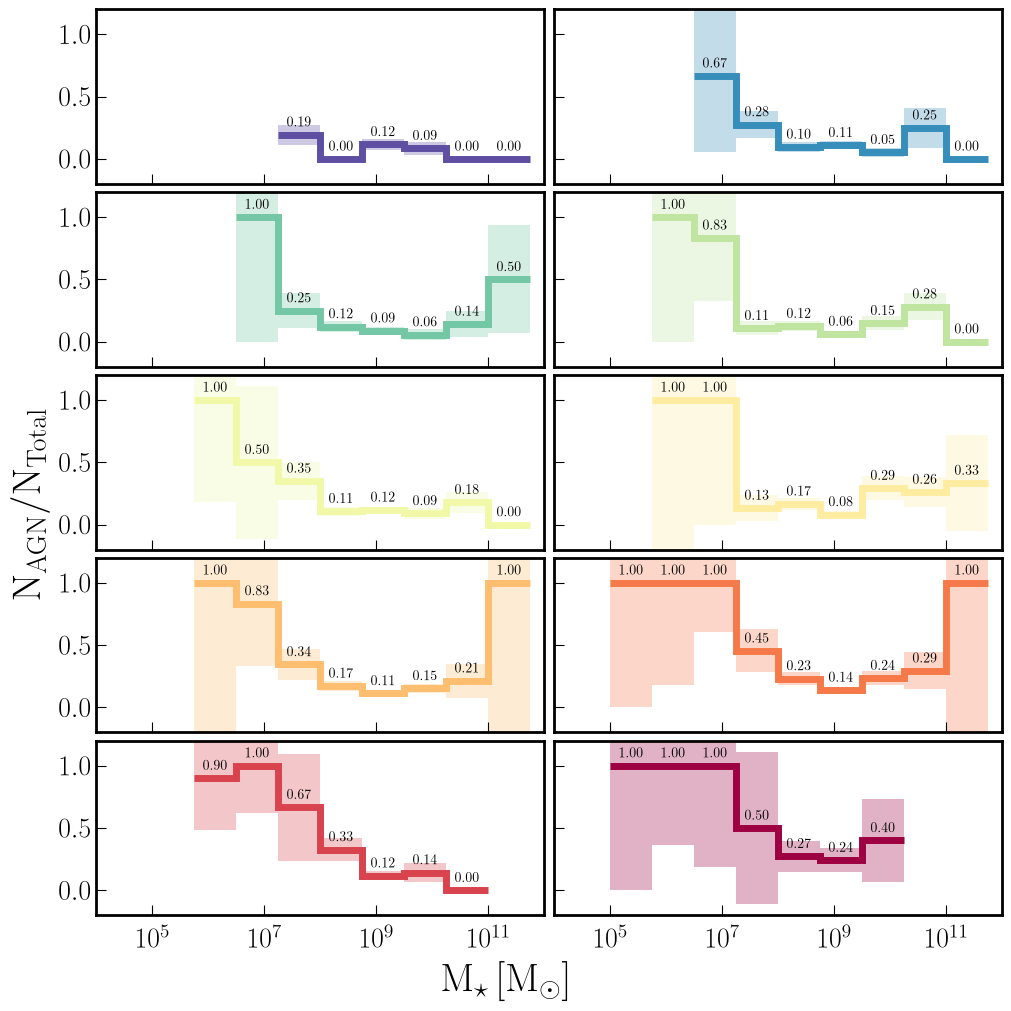

In [47]:
fig, ax = plt.subplots(5,2, figsize = (10,10), sharex=True, sharey=True, layout='constrained')
ax = ax.flatten()
# fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0.5)

cols = get_n_colors(cmap_name="Spectral_r", n=len(zmids))

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    stellarAGN_counts, stellarAGN_bin_edges = np.histogram(
            np.log10(prospect_sample[zidx]["StellarMassQ50"][prospect_sample["FitType"][zidx] == "StellarAGN"]), 
            bins=sm_bins
        )
    tot_counts, tot_bin_edges = np.histogram(
            np.log10(prospect_sample[zidx]["StellarMassQ50"]), 
            bins=sm_bins
        ) 

    ratio = stellarAGN_counts/tot_counts
    # ratio[tot_counts <= 1] = np.nan
    print(
        f"{np.nanmedian(ratio[sm_mids < 9 ]):.3f}" + " - " + f"{np.nanmedian(ratio[sm_mids >= 9 ]):.3f}" + " - " + f"{np.nanmedian(ratio):.3f}"
    )

    # ratio[tot_counts <= 1] = np.nan
    # print(
    #     f"{np.nanmedian(ratio[sm_mids < 9 ]):.3f}" + " - " + f"{np.nanmedian(ratio[sm_mids >= 9 ]):.3f}"
    # )
    print("....")

    stellarAGN_err = np.sqrt(stellarAGN_counts)
    tot_err = np.sqrt(tot_counts)

    ratio_err = stellarAGN_counts/tot_counts * np.sqrt((stellarAGN_err / stellarAGN_counts)**2 + (tot_err / tot_counts)**2)

    edges = 10**sm_bins                              # sm_bins = your log10 bin edges, length n+1


    ax[i].stairs(ratio, edges, color=cols[i], lw=5,baseline=None)
    ax[i].stairs(ratio + ratio_err, edges, baseline=ratio - ratio_err,
                fill=True, color=cols[i], alpha=0.3)

    ax[i].set_xscale("log")

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([-0.2, 1.2])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([0, 0.5, 1.0])

    x = 10**sm_mids
    y = ratio

    for xj, yj in zip(x, y):
        if np.isfinite(yj):
            ax[i].annotate(f"{yj:.2f}", (xj, yj),
                        textcoords="offset points", xytext=(0, 6),
                        ha="center", fontsize=10)

    # ax[i].text(
    #     0.05,
    #     0.88,
    #     rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
    #     transform=ax[i].transAxes,
    #     fontsize = 16
    # )

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{N_{AGN} / N_{Total}}$")
 
fig.show()

## Vs. redshift distributions

In [ ]:
cols = ["tab:blue" if x == "Stellar" else "tab:red" for x in prospect_sample['FitType']]

fig, ax = plt.subplots(4, 1, figsize = (10,10), layout = 'constrained', sharex = True)
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

ax[0].errorbar(
    prospect_sample["zQ50"][prospect_sample["FitType"] == "Stellar"], 
    prospect_sample["UV1500Q50"][prospect_sample["FitType"] == "Stellar"], 
    xerr = [
        prospect_sample["z_lo"][prospect_sample["FitType"] == "Stellar"], 
        prospect_sample["z_hi"][prospect_sample["FitType"] == "Stellar"]
    ],
    yerr = [
        prospect_sample["UV1500_hi"][prospect_sample["FitType"] == "Stellar"], 
        prospect_sample["UV1500_lo"][prospect_sample["FitType"] == "Stellar"]
    ],
    ls = 'none',
    marker = "o", 
    markersize = 8,
    markerfacecolor = "tab:blue",
    markeredgecolor = lighten_color("tab:blue", 1.5),
    ecolor = lighten_color("tab:blue", 1.5), 
    alpha = 0.4,
    capsize = 3
)
ax[0].errorbar(
    prospect_sample["zQ50"][prospect_sample["FitType"] == "StellarAGN"], 
    prospect_sample["UV1500Q50"][prospect_sample["FitType"] == "StellarAGN"], 
    xerr = [
        prospect_sample["z_lo"][prospect_sample["FitType"] == "StellarAGN"], 
        prospect_sample["z_hi"][prospect_sample["FitType"] == "StellarAGN"]
    ],
    yerr = [
        prospect_sample["UV1500_lo"][prospect_sample["FitType"] == "StellarAGN"], 
        prospect_sample["UV1500_hi"][prospect_sample["FitType"] == "StellarAGN"]
    ],
    ls = 'none',
    marker = "o", 
    markersize = 8,
    markerfacecolor = "tab:red",
    markeredgecolor = lighten_color("tab:red", 1.5),
    ecolor = lighten_color("tab:red", 1.5), 
    alpha = 0.4,
    capsize = 3,
    zorder = 200
)
ax[0].set_ylim([-5, -23])

ax[1].errorbar(
    prospect_sample["zQ50"][prospect_sample["FitType"] == "Stellar"], 
    prospect_sample["StellarMassQ50"][prospect_sample["FitType"] == "Stellar"], 
    xerr = [
        prospect_sample["z_lo"][prospect_sample["FitType"] == "Stellar"], 
        prospect_sample["z_hi"][prospect_sample["FitType"] == "Stellar"]
    ],
    yerr = [
        prospect_sample["StellarMass_lo"][prospect_sample["FitType"] == "Stellar"], 
        prospect_sample["StellarMass_hi"][prospect_sample["FitType"] == "Stellar"]
    ],
    ls = 'none',
    marker = "o", 
    markersize = 8,
    markerfacecolor = "tab:blue",
    markeredgecolor = lighten_color("tab:blue", 1.5),
    ecolor = lighten_color("tab:blue", 1.5), 
    alpha = 0.4,
    capsize = 3
)
ax[1].errorbar(
    prospect_sample["zQ50"][prospect_sample["FitType"] == "StellarAGN"], 
    prospect_sample["StellarMassQ50"][prospect_sample["FitType"] == "StellarAGN"], 
    xerr = [
        prospect_sample["z_lo"][prospect_sample["FitType"] == "StellarAGN"], 
        prospect_sample["z_hi"][prospect_sample["FitType"] == "StellarAGN"]
    ],
    yerr = [
        prospect_sample["StellarMass_lo"][prospect_sample["FitType"] == "StellarAGN"], 
        prospect_sample["StellarMass_hi"][prospect_sample["FitType"] == "StellarAGN"]
    ],
    ls = 'none',
    marker = "o", 
    markersize = 8,
    markerfacecolor = "tab:red",
    markeredgecolor = lighten_color("tab:red", 1.5),
    ecolor = lighten_color("tab:red", 1.5), 
    alpha = 0.4,
    capsize = 3,
    zorder = 200
)
ax[1].set_yscale('log')
ax[1].set_ylim([1e3, 2e12])


ax[2].errorbar(
    starforming_sample["zQ50"][starforming_sample["FitType"] == "Stellar"], 
    starforming_sample["SFR10Q50"][starforming_sample["FitType"] == "Stellar"], 
    xerr = [
        starforming_sample["z_lo"][starforming_sample["FitType"] == "Stellar"], 
        starforming_sample["z_hi"][starforming_sample["FitType"] == "Stellar"]
    ],
    yerr = [
        starforming_sample["SFR10_lo"][starforming_sample["FitType"] == "Stellar"], 
        starforming_sample["SFR10_hi"][starforming_sample["FitType"] == "Stellar"]
    ],
    ls = 'none',
    marker = "o", 
    markersize = 8,
    markerfacecolor = "tab:blue",
    markeredgecolor = lighten_color("tab:blue", 1.5),
    ecolor = lighten_color("tab:blue", 1.5), 
    alpha = 0.4,
    capsize = 3
)
ax[2].errorbar(
    starforming_sample["zQ50"][starforming_sample["FitType"] == "StellarAGN"], 
    starforming_sample["SFR10Q50"][starforming_sample["FitType"] == "StellarAGN"], 
    xerr = [
        starforming_sample["z_lo"][starforming_sample["FitType"] == "StellarAGN"], 
        starforming_sample["z_hi"][starforming_sample["FitType"] == "StellarAGN"]
    ],
    yerr = [
        starforming_sample["SFR10_lo"][starforming_sample["FitType"] == "StellarAGN"], 
        starforming_sample["SFR10_hi"][starforming_sample["FitType"] == "StellarAGN"]
    ],
    ls = 'none',
    marker = "o", 
    markersize = 8,
    markerfacecolor = "tab:red",
    markeredgecolor = lighten_color("tab:red", 1.5),
    ecolor = lighten_color("tab:red", 1.5), 
    alpha = 0.4,
    capsize = 3,
    zorder = 200
)
# ax[2].scatter(
#     quenched_sample["zQ50"][quenched_sample["FitType"] == "Stellar"], 
#     minimum_SFR10_vals[quenched_sample["FitType"] == "Stellar"], 
#     marker = down_arrow_marker, 
#     s = 1000,
#     facecolor = "tab:blue",
#     edgecolor = lighten_color("tab:blue", 1.5),
#     alpha = 0.4,
# )
# ax[2].scatter(
#     quenched_sample["zQ50"][quenched_sample["FitType"] == "StellarAGN"], 
#     minimum_SFR10_vals[quenched_sample["FitType"] == "StellarAGN"], 
#     marker = down_arrow_marker, 
#     s = 1000,
#     facecolor = "tab:red",
#     edgecolor = lighten_color("tab:red", 1.5),
#     alpha = 0.4,
# )
ax[2].set_yscale('log')
ax[2].set_ylim([8e-6, 4e3])

ax[3].errorbar(
    starforming_sample["zQ50"][starforming_sample["FitType"] == "Stellar"], 
    starforming_sample["AGNlumQ50"][starforming_sample["FitType"] == "Stellar"], 
    xerr = [
        starforming_sample["z_lo"][starforming_sample["FitType"] == "Stellar"], 
        starforming_sample["z_hi"][starforming_sample["FitType"] == "Stellar"]
    ],
    yerr = [
        starforming_sample["AGNlum_lo"][starforming_sample["FitType"] == "Stellar"], 
        starforming_sample["AGNlum_hi"][starforming_sample["FitType"] == "Stellar"]
    ],
    ls = 'none',
    marker = "o", 
    markersize = 8,
    markerfacecolor = "tab:blue",
    markeredgecolor = lighten_color("tab:blue", 1.5),
    ecolor = lighten_color("tab:blue", 1.5), 
    alpha = 0.4,
    capsize = 3
)
ax[3].errorbar(
    starforming_sample["zQ50"][starforming_sample["FitType"] == "StellarAGN"], 
    starforming_sample["AGNlumQ50"][starforming_sample["FitType"] == "StellarAGN"], 
    xerr = [
        starforming_sample["z_lo"][starforming_sample["FitType"] == "StellarAGN"], 
        starforming_sample["z_hi"][starforming_sample["FitType"] == "StellarAGN"]
    ],
    yerr = [
        starforming_sample["AGNlum_lo"][starforming_sample["FitType"] == "StellarAGN"], 
        starforming_sample["AGNlum_hi"][starforming_sample["FitType"] == "StellarAGN"]
    ],
    ls = 'none',
    marker = "o", 
    markersize = 8,
    markerfacecolor = "tab:red",
    markeredgecolor = lighten_color("tab:red", 1.5),
    ecolor = lighten_color("tab:red", 1.5), 
    alpha = 0.4,
    capsize = 3,
    zorder = 200
)
ax[3].set_yscale('log')
ax[3].set_ylim([2e35, 6e47])

ax[0].set_xlim([zbins[0]-0.5, zbins[-1]+0.5])
# ax[0].set_xlim([-0.5, zbins[-1]+0.5])

ax[0].set_ylabel("MUV [mag]")
ax[1].set_ylabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
ax[2].set_ylabel(r"$\mathrm{SFR_{10} \, [M_{\odot} \, yr^{-1}]}$")
ax[3].set_ylabel(r"$\mathrm{L_{AGN} \, [erg \, s^{-1}]}$")

ax_top = ax[0].secondary_xaxis('top')
ax_top.set_xticks(ax[0].get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax[0].get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

custom_lines = [Line2D([0], [0], color="tab:blue", marker = "o"),
                Line2D([0], [0], color="tab:red", marker = "o")]
ax[0].legend(custom_lines, ["Stellar", "Stellar+AGN"], fontsize = 16, fancybox=True)

fig.supxlabel("Redshift")

fig.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/astro_quantities_vs_redshift.png", 
    dpi = 240,
    bbox_inches="tight"
)

# SFR-Mstar

In [42]:
xm = np.linspace(0, 15, 100)

def dpl_func(x, parm):
    S0, M0, alpha, beta = parm

    mu = 10**(x-M0)
    SFR = S0 - np.log10( mu**(-1.0*alpha) + mu**(-1.0*beta) )

    return(SFR)

thorne21 = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/sfs/TableD3_SFMSValues.txt", delimiter="\t")

In [43]:
# lrd_test = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/prospect/photoZ_bc03_snorm_LRDMBB_norm_eazy_lrd_astro_cat.csv")

Median AGNlum =  41.87510719224076 
Median AGNlum =  41.45592028684538 
Median AGNlum =  41.64200194970022 
Median AGNlum =  42.13685372382617 
Median AGNlum =  42.249115285041654 
Median AGNlum =  43.044936046272554 
Median AGNlum =  42.80779459041783 
Median AGNlum =  43.533313867206196 
Median AGNlum =  43.51924060427375 
Median AGNlum =  44.03397305353096 


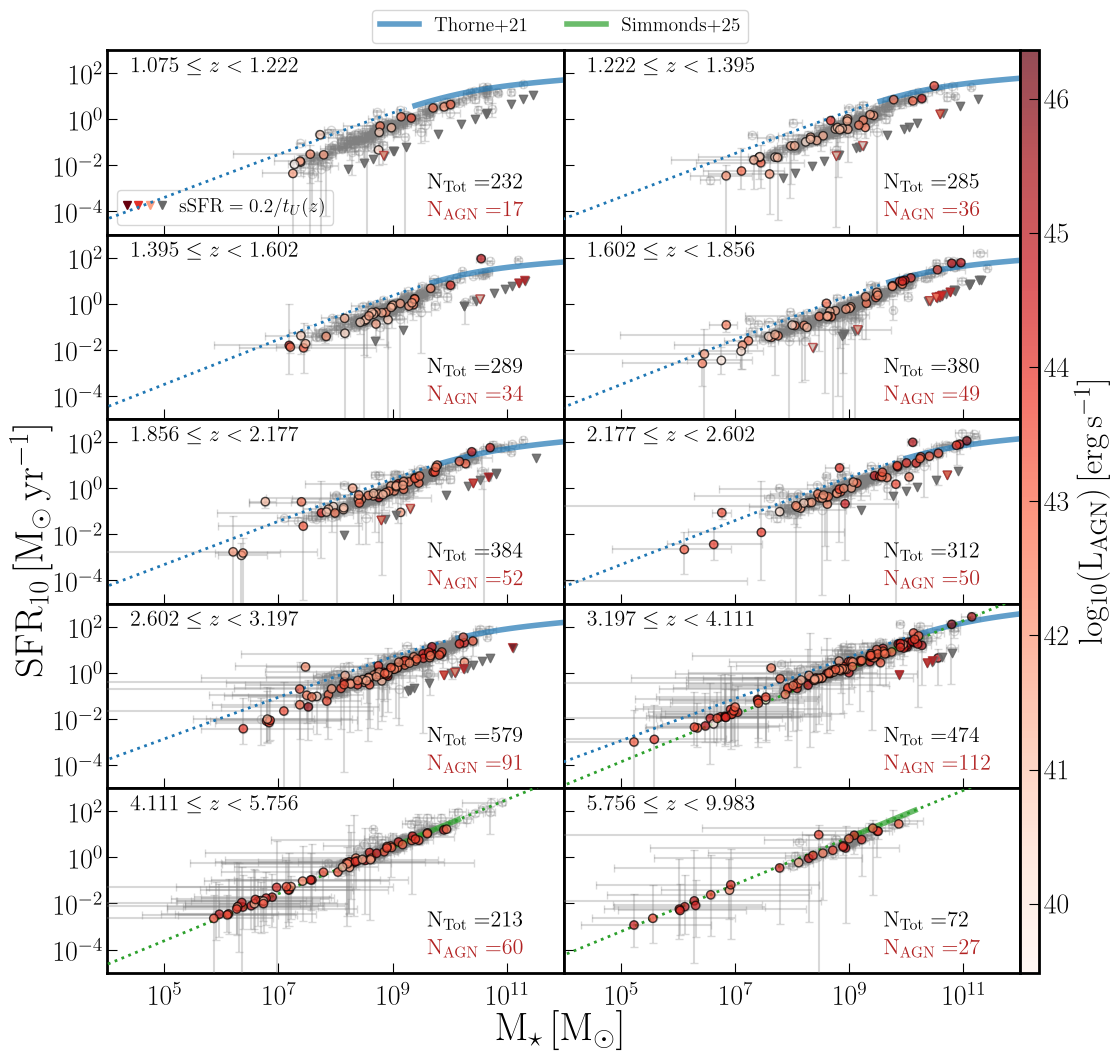

In [44]:
fig, ax = plt.subplots(5,2, figsize = (11,10), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

tot_agnlum = prospect_sample["AGNlumQ50"]

for i in range(len(zmids)):
    zidx = (starforming_sample["zQ50"] >= zbins[i]) & (starforming_sample["zQ50"] < zbins[i+1])
    zidx_quenched = (quenched_sample["zQ50"] >= zbins[i]) & (quenched_sample["zQ50"] < zbins[i+1])
    zidx_total = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        starforming_sample["StellarMassQ50"][zidx],
        starforming_sample["SFR10Q50"][zidx],
        xerr = [starforming_sample["StellarMass_lo"][zidx], starforming_sample["StellarMass_hi"][zidx]],
        yerr = [starforming_sample["SFR10_lo"][zidx], starforming_sample["SFR10_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "grey",
        ecolor = "grey",
        capsize = 3,
        alpha = 0.3,
        zorder = 50
    )

    # zidx_test = (lrd_test["zQ50"] >= zbins[i]) & (lrd_test["zQ50"] < zbins[i+1])
    # ax[i].scatter(
    #     lrd_test["StellarMassQ50"][zidx_test],
    #     lrd_test["SFR10Q50"][zidx_test],
    #     marker = "*", 
    #     s = 100,
    #     color = "magenta"
    # )

    print( f"Median AGNlum =  {np.nanmedian(np.log10(starforming_sample["AGNlumQ50"][zidx]))} ")

    sc_ = ax[i].scatter(
        starforming_sample["StellarMassQ50"][zidx],
        starforming_sample["SFR10Q50"][zidx],
        c = np.log10(starforming_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        # vmin = 41,
        # vmax = 47,
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 200, 
        cmap='Reds',
        alpha = 0.7
    )

    quench_ = ax[i].scatter(
        quenched_sample["StellarMassQ50"][zidx_quenched],
        minimum_SFR10_vals[zidx_quenched],
        zorder = 200, 
        color='dimgrey',
        alpha = 0.9,
        marker = "v",
        # marker = down_arrow_marker,
        edgecolor = "dimgrey",
        # s = 800
    )
    sc_quenched_ = ax[i].scatter(
        quenched_sample["StellarMassQ50"][zidx_quenched],
        minimum_SFR10_vals[zidx_quenched],
        c = np.log10(quenched_sample["AGNlumQ50"][zidx_quenched]),
        # vmin = 41,
        # vmax = 47,
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 200, 
        cmap='Reds',
        alpha = 0.7,
        marker = "v",
        # marker = down_arrow_marker,
        edgecolor = "firebrick",
        # s = 800
    )

    
    # thorne+21
    if zmids[i] < 4:
        thorne21_mass_complete_idx = xm >= 0.25*lbt_mids[i] + 7.25
        S0 = np.interp(
                    xp = thorne21["zmed"],
                    fp = thorne21["S0"],
                    x = zmids[i]
                )
        M0 = np.interp(
                        xp = thorne21["zmed"],
                        fp = thorne21["M0"],
                        x = zmids[i]
                    )
        alpha = np.interp(
                        xp = thorne21["zmed"],
                        fp = thorne21["alpha"],
                        x = zmids[i]
                    )
        beta = np.interp(
                        xp = thorne21["zmed"],
                        fp = thorne21["beta"],
                        x = zmids[i]
                    )
        ax[i].plot(
            10**xm[thorne21_mass_complete_idx],
            10**dpl_func(x=xm[thorne21_mass_complete_idx], parm=[S0, M0, alpha, beta]),
            color = "tab:blue", 
            ls = "-",
            lw = 4,
            alpha = 0.7,
            zorder = 100,
            label = "Thorne+21"
        )
        ax[i].plot(
            10**xm[~thorne21_mass_complete_idx],
            10**dpl_func(x=xm[~thorne21_mass_complete_idx], parm=[S0, M0, alpha, beta]),
            color = "tab:blue", 
            ls = ":",
            lw = 2,
            zorder = 100,
            # label = "Thorne+21"
        )
        
    # Simmonds+25
    if zmids[i] >= 3:
        sb = 0.05
        beta = 0.02
        mu = 2.30

        simmonds25_mass_complete_idx = (xm >= 9.0) & (xm < 10.3)
        ssfr = sb * (10**xm / 10**10)**beta * (1 + zmids[i])**mu

        ax[i].plot(
            10**xm[simmonds25_mass_complete_idx],
            ssfr[simmonds25_mass_complete_idx] * 10**xm[simmonds25_mass_complete_idx] / 1e9,
            color = "tab:green",
            ls = "-",
            lw = 4,
            alpha = 0.7,
            zorder = 100,
            label = "Simmonds+25"
        )

        ax[i].plot(
            10**xm[~simmonds25_mass_complete_idx],
            ssfr[~simmonds25_mass_complete_idx] * 10**xm[~simmonds25_mass_complete_idx] / 1e9,
            color = "tab:green",
            ls = ":",
            lw = 2,
            zorder = 100,
            # label = "Simmonds+25"
        )

    ax[i].text(
        0.05,
        0.88,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.7,
        0.25,
        r"$\mathrm{N_{Tot} = }$" + f"{sum(zidx_total)}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.7,
        0.10,
        r"$\mathrm{N_{AGN} = }$" + f"{sum(prospect_sample["FitType"][zidx_total] == "StellarAGN")}",
        transform=ax[i].transAxes,
        fontsize = 16,
        color = "firebrick"
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([1e-5, 1e3])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([1e-4, 1e-2, 1e0, 1e2])

# cbar_ax = fig.add_axes([0.87, 0.05, 0.02, 0.9])  # [left, bottom, width, height]

handles, labels = ax[7].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.05),  # above the figure
    ncol = 2,
    # ncol=len(labels),            # optional: put all entries on one row
    fontsize=14,
    fancybox=True,
    frameon=True
)

# plt.rcParams["text.usetex"] = False
# custom_lines = [
#     Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[3],
#            marker='$\u2193$', markersize=8*2, linestyle='None'),
#     Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[2],
#            marker='$\u2193$', markersize=8*2, linestyle='None'),
#     Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[1],
#            marker='$\u2193$', markersize=8*2, linestyle='None'),
#     Line2D([0], [0], color="dimgrey",
#            marker='$\u2193$', markersize=8*2, linestyle='None'),
# ]
# plt.rcParams["text.usetex"] = True
custom_lines = [
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[3],
           marker='v', markersize=3*2, linestyle='None'),
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[2],
           marker='v', markersize=3*2, linestyle='None'),
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[1],
           marker='v', markersize=3*2, linestyle='None'),
    Line2D([0], [0], color="dimgrey",
           marker='v', markersize=3*2, linestyle='None'),
]

ax[0].legend(
    [tuple(custom_lines)],
    # ["Upper limits"],
    [r"$\mathrm{sSFR} = 0.2/t_{U}(z)$"],
    fontsize=14,
    frameon=True,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    handlelength=2,   # widen the entry so 3 markers don't overlap/crowd
    loc = "lower left"
)

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{SFR_{10} \, [M_{\odot} \, yr^{-1}]}$")

fig.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/sfr-mstar-z.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


## SFR100

Median AGNlum =  42.05235413567523 
Median AGNlum =  42.429504976021185 
Median AGNlum =  42.62446607694254 
Median AGNlum =  42.520277844843264 
Median AGNlum =  42.890128776110195 
Median AGNlum =  43.62766666897326 
Median AGNlum =  43.62977831181739 
Median AGNlum =  43.95514822391863 
Median AGNlum =  44.00547877565528 
Median AGNlum =  44.19525693307765 


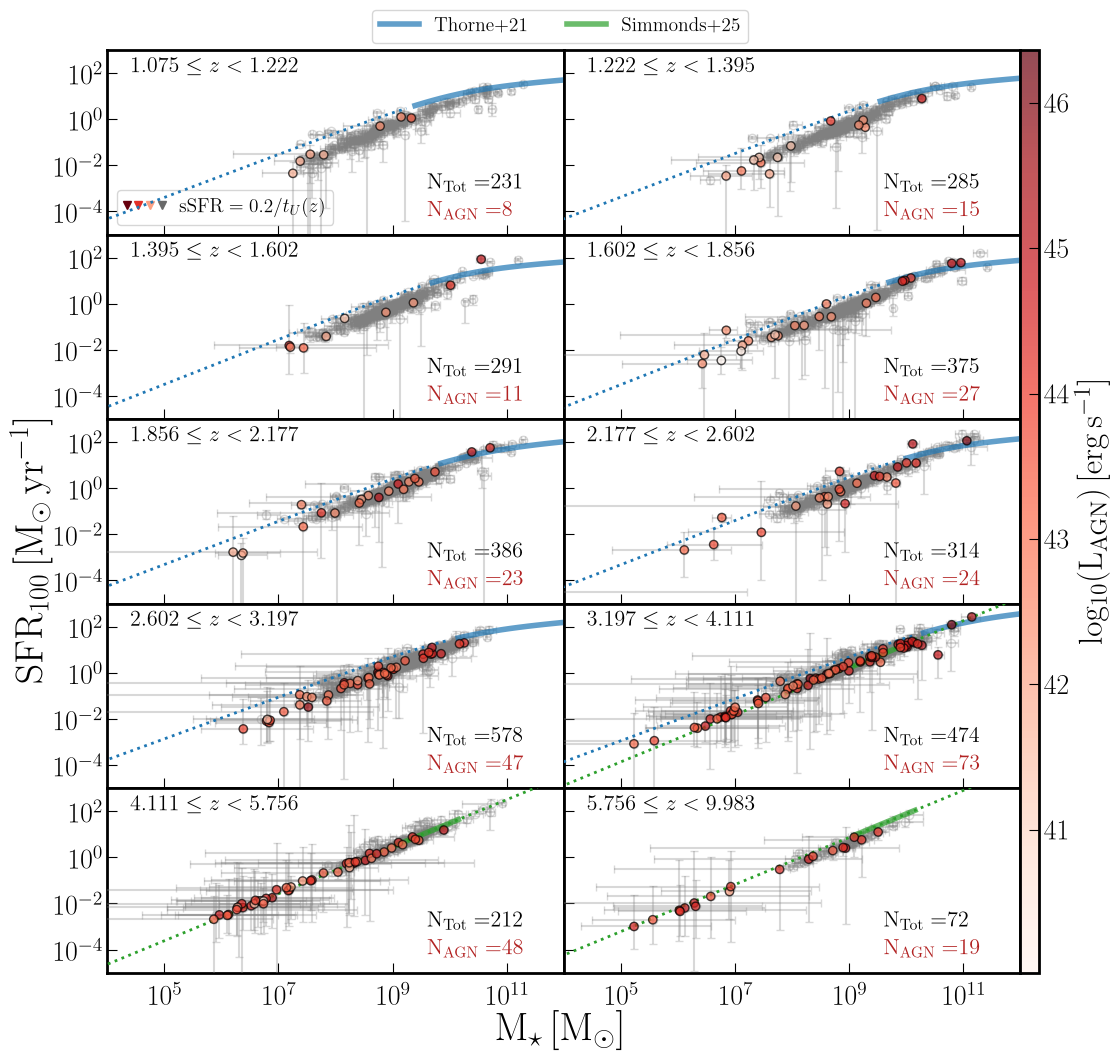

In [22]:
fig, ax = plt.subplots(5,2, figsize = (11,10), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

tot_agnlum = prospect_sample["AGNlumQ50"]

for i in range(len(zmids)):
    zidx = (starforming_sample["zQ50"] >= zbins[i]) & (starforming_sample["zQ50"] < zbins[i+1])
    zidx_quenched = (quenched_sample["zQ50"] >= zbins[i]) & (quenched_sample["zQ50"] < zbins[i+1])
    zidx_total = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        starforming_sample["StellarMassQ50"][zidx],
        starforming_sample["SFR100Q50"][zidx],
        xerr = [starforming_sample["StellarMass_lo"][zidx], starforming_sample["StellarMass_hi"][zidx]],
        yerr = [starforming_sample["SFR100_lo"][zidx], starforming_sample["SFR100_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "grey",
        ecolor = "grey",
        capsize = 3,
        alpha = 0.3,
        zorder = 50
    )

    # zidx_test = (lrd_test["zQ50"] >= zbins[i]) & (lrd_test["zQ50"] < zbins[i+1])
    # ax[i].scatter(
    #     lrd_test["StellarMassQ50"][zidx_test],
    #     lrd_test["SFR100Q50"][zidx_test],
    #     marker = "*", 
    #     s = 100,
    #     color = "magenta"
    # )

    print( f"Median AGNlum =  {np.nanmedian(np.log10(starforming_sample["AGNlumQ50"][zidx]))} ")

    sc_ = ax[i].scatter(
        starforming_sample["StellarMassQ50"][zidx],
        starforming_sample["SFR100Q50"][zidx],
        c = np.log10(starforming_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        # vmin = 41,
        # vmax = 47,
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 200, 
        cmap='Reds',
        alpha = 0.7
    )

    # quench_ = ax[i].scatter(
    #     quenched_sample["StellarMassQ50"][zidx_quenched],
    #     minimum_SFR100_vals[zidx_quenched],
    #     zorder = 200, 
    #     color='dimgrey',
    #     alpha = 0.9,
    #     marker = "v",
    #     # marker = down_arrow_marker,
    #     edgecolor = "dimgrey",
    #     # s = 800
    # )
    # sc_quenched_ = ax[i].scatter(
    #     quenched_sample["StellarMassQ50"][zidx_quenched],
    #     minimum_SFR100_vals[zidx_quenched],
    #     c = np.log10(quenched_sample["AGNlumQ50"][zidx_quenched]),
    #     # vmin = 41,
    #     # vmax = 47,
    #     vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
    #     vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
    #     zorder = 200, 
    #     cmap='Reds',
    #     alpha = 0.7,
    #     marker = "v",
    #     # marker = down_arrow_marker,
    #     edgecolor = "firebrick",
    #     # s = 800
    # )

    
    # thorne+21
    if zmids[i] < 4:
        thorne21_mass_complete_idx = xm >= 0.25*lbt_mids[i] + 7.25
        S0 = np.interp(
                    xp = thorne21["zmed"],
                    fp = thorne21["S0"],
                    x = zmids[i]
                )
        M0 = np.interp(
                        xp = thorne21["zmed"],
                        fp = thorne21["M0"],
                        x = zmids[i]
                    )
        alpha = np.interp(
                        xp = thorne21["zmed"],
                        fp = thorne21["alpha"],
                        x = zmids[i]
                    )
        beta = np.interp(
                        xp = thorne21["zmed"],
                        fp = thorne21["beta"],
                        x = zmids[i]
                    )
        ax[i].plot(
            10**xm[thorne21_mass_complete_idx],
            10**dpl_func(x=xm[thorne21_mass_complete_idx], parm=[S0, M0, alpha, beta]),
            color = "tab:blue", 
            ls = "-",
            lw = 4,
            alpha = 0.7,
            zorder = 100,
            label = "Thorne+21"
        )
        ax[i].plot(
                    10**xm[~thorne21_mass_complete_idx],
                    10**dpl_func(x=xm[~thorne21_mass_complete_idx], parm=[S0, M0, alpha, beta]),
                    color = "tab:blue", 
                    ls = ":",
                    lw = 2,
                    zorder = 100,
                    # label = "Thorne+21"
                )
        
    # Simmonds+25
    if zmids[i] >= 3:
        sb = 0.05,
        beta = 0.02
        mu = 2.30

        simmonds25_mass_complete_idx = (xm >= 9.0) & (xm < 10.3)

        ssfr = sb * (10**xm / 10**10)**beta * (1 + zmids[i])**mu
        ax[i].plot(
            10**xm[simmonds25_mass_complete_idx],
            ssfr[simmonds25_mass_complete_idx] * 10**xm[simmonds25_mass_complete_idx] / 1e9,
            color = "tab:green",
            ls = "-",
            lw = 4,
            alpha = 0.7,
            zorder = 100,
            label = "Simmonds+25"
        )

        ax[i].plot(
            10**xm[~simmonds25_mass_complete_idx],
            ssfr[~simmonds25_mass_complete_idx] * 10**xm[~simmonds25_mass_complete_idx] / 1e9,
            color = "tab:green",
            ls = ":",
            lw = 2,
            zorder = 100,
            # label = "Simmonds+25"
        )

    ax[i].text(
        0.05,
        0.88,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.7,
        0.25,
        r"$\mathrm{N_{Tot} = }$" + f"{sum(zidx_total)}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.7,
        0.10,
        r"$\mathrm{N_{AGN} = }$" + f"{sum(prospect_sample["FitType"][zidx_total] == "StellarAGN")}",
        transform=ax[i].transAxes,
        fontsize = 16,
        color = "firebrick"
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([1e-5, 1e3])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([1e-4, 1e-2, 1e0, 1e2])

# cbar_ax = fig.add_axes([0.87, 0.05, 0.02, 0.9])  # [left, bottom, width, height]

handles, labels = ax[7].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.05),  # above the figure
    ncol = 2,
    # ncol=len(labels),            # optional: put all entries on one row
    fontsize=14,
    fancybox=True,
    frameon=True
)

# plt.rcParams["text.usetex"] = False
# custom_lines = [
#     Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[3],
#            marker='$\u2193$', markersize=8*2, linestyle='None'),
#     Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[2],
#            marker='$\u2193$', markersize=8*2, linestyle='None'),
#     Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[1],
#            marker='$\u2193$', markersize=8*2, linestyle='None'),
#     Line2D([0], [0], color="dimgrey",
#            marker='$\u2193$', markersize=8*2, linestyle='None'),
# ]
# plt.rcParams["text.usetex"] = True
custom_lines = [
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[3],
           marker='v', markersize=3*2, linestyle='None'),
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[2],
           marker='v', markersize=3*2, linestyle='None'),
    Line2D([0], [0], color=get_n_colors(cmap_name="Reds", n=4)[1],
           marker='v', markersize=3*2, linestyle='None'),
    Line2D([0], [0], color="dimgrey",
           marker='v', markersize=3*2, linestyle='None'),
]

ax[0].legend(
    [tuple(custom_lines)],
    # ["Upper limits"],
    [r"$\mathrm{sSFR} = 0.2/t_{U}(z)$"],
    fontsize=14,
    frameon=True,
    handler_map={tuple: HandlerTuple(ndivide=None)},
    handlelength=2,   # widen the entry so 3 markers don't overlap/crowd
    loc = "lower left"
)

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{SFR_{100} \, [M_{\odot} \, yr^{-1}]}$")

fig.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/sfr100-mstar-z.pdf", 
    dpi = 240,
    bbox_inches="tight"
)


In [ ]:
fig, ax = plt.subplots(5,2, figsize = (10,10), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

tot_agnlum = prospect_sample["AGNlumQ50"]

for i in range(len(zmids)):
    zidx = (starforming_sample["zQ50"] >= zbins[i]) & (starforming_sample["zQ50"] < zbins[i+1])
    zidx_quenched = (quenched_sample["zQ50"] >= zbins[i]) & (quenched_sample["zQ50"] < zbins[i+1])
    zidx_total = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    print(
        np.median(
            starforming_sample["SFR10Q50"][zidx] / starforming_sample["SFR100Q50"][zidx]
        )
    )
    ax[i].hist(
        (starforming_sample["SFR10Q50"][zidx] / starforming_sample["SFR100Q50"][zidx]), 
        bins = np.linspace(0,2,50)
    )

    ax[i].set_xlim([0.5, 1.5])
    ax[i].set_ylim([2,5e2])
    ax[i].set_yscale('log')

# Mstar LAGN

In [ ]:
fig, ax = plt.subplots(5,2, figsize = (9,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["AGNlumQ50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [prospect_sample["AGNlum_lo"][zidx], prospect_sample["AGNlum_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.8,
        f"N = {sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx]))}",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([8e35, 2e48])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{L_{AGN} \, [erg \, s^{-1}]}$", x = -0.06)

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/sfr-mstar-z.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

# Mstar vs MUV

In [ ]:
fig, ax = plt.subplots(5,2, figsize = (10,10), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

MUV_AGN_ratio = pow(10, -0.4 * (prospect_sample["UV1500AGNQ50"] - prospect_sample["UV1500Q50"]))

xMstar = np.linspace(1.5, 15.5, 100)

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [prospect_sample["UV1500_lo"][zidx], prospect_sample["UV1500_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )

    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        c = MUV_AGN_ratio[zidx],
        edgecolor = "black",
        vmin = 0.0,
        vmax = 1.0,
        zorder = 100, 
        cmap='Reds',
        alpha = 1.0
    )

    if i == 7:
        ax[i].plot(
            10**xMstar,
            (xMstar - 9.25)/-0.6 - 19.5,
            color = "tab:cyan",
            ls = "--",
            label = "Simmonds+24 - Best fit",
            zorder = 200
        )
        ax[i].legend(
            fontsize = 14,
            frameon=True,
            loc = "upper left"
        )
    if i == 8:
        ax[i].plot(
            10**xMstar,
            (xMstar - 9.06)/-0.69 - 19.5,
            color = "tab:cyan",
            ls = "--",
            label = "Simmonds+24 - Best fit",
            zorder = 200
        )

    ax[i].text(
        0.1,
        0.2,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].text(
        0.1,
        0.1,
        f"N = {sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx]))}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].set_xscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([-4.7, -25.1])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([-10, -15, -20, -24])

cbar = fig.colorbar(sc_, ax = ax, label=r'$f\mathrm{_{AGN}^{UV}}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{MUV \, [mag]}$", x = -0.05)

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/MUV-mstar-z.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

In [ ]:
prospect_sample["AGN_Dale_fracQ50"]

In [ ]:
fig, ax = plt.subplots(5,2, figsize = (10,10), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_sample["zQ50"] >= zbins[0]) & (prospect_sample["zQ50"] < zbins[-1])

MUV_AGN_ratio = pow(10, -0.4 * (prospect_sample["UV1500AGNQ50"] - prospect_sample["UV1500Q50"]))

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [prospect_sample["UV1500_lo"][zidx], prospect_sample["UV1500_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )

    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        prospect_sample["UV1500Q50"][zidx],
        c = [np.nan if x == 0 else x for x in prospect_sample["AGN_Dale_fracQ50"][zidx]],
        edgecolor = "black",
        vmin = 0.0,
        vmax = 1.0,
        zorder = 100, 
        cmap='Reds',
        alpha = 1.0
    )
    ax[i].text(
            0.1,
            0.2,
            rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
            transform=ax[i].transAxes,
            fontsize = 16
    )
    ax[i].text(
        0.1,
        0.1,
        f"N = {sum(~np.isnan(prospect_sample["AGNlumQ50"][zidx]))}",
        transform=ax[i].transAxes,
        fontsize = 16
    )
    ax[i].set_xscale('log')

    ax[i].set_xlim([1e4, 1e12])
    ax[i].set_ylim([-4.7, -25.1])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([-10, -15, -20])

cbar = fig.colorbar(sc_, ax = ax, label=r'$f\mathrm{_{AGN}^{5-20\mu m}}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{MUV \, [mag]}$", x = -0.05)

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/MUV-mstar-z_AGNfrac.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

# Mstar vs. accretion rates

In [27]:
lrd_fritz = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/prospect/photoZ_bc03_snorm_fritz_norm_eazy_lrd_astro_cat.csv")

In [28]:
sfr_bhar_dpl_fits = []

for i in range(len(zmids)):
    ff = pd.read_hdf(
                h5file, 
                f"SFRBHAR/fits/{i+1}"
            )
    sfr_bhar_dpl_fits.append(ff)
        
sfr_bhar_dpl_params = pd.read_hdf(h5file, "SFRBHAR/Params")

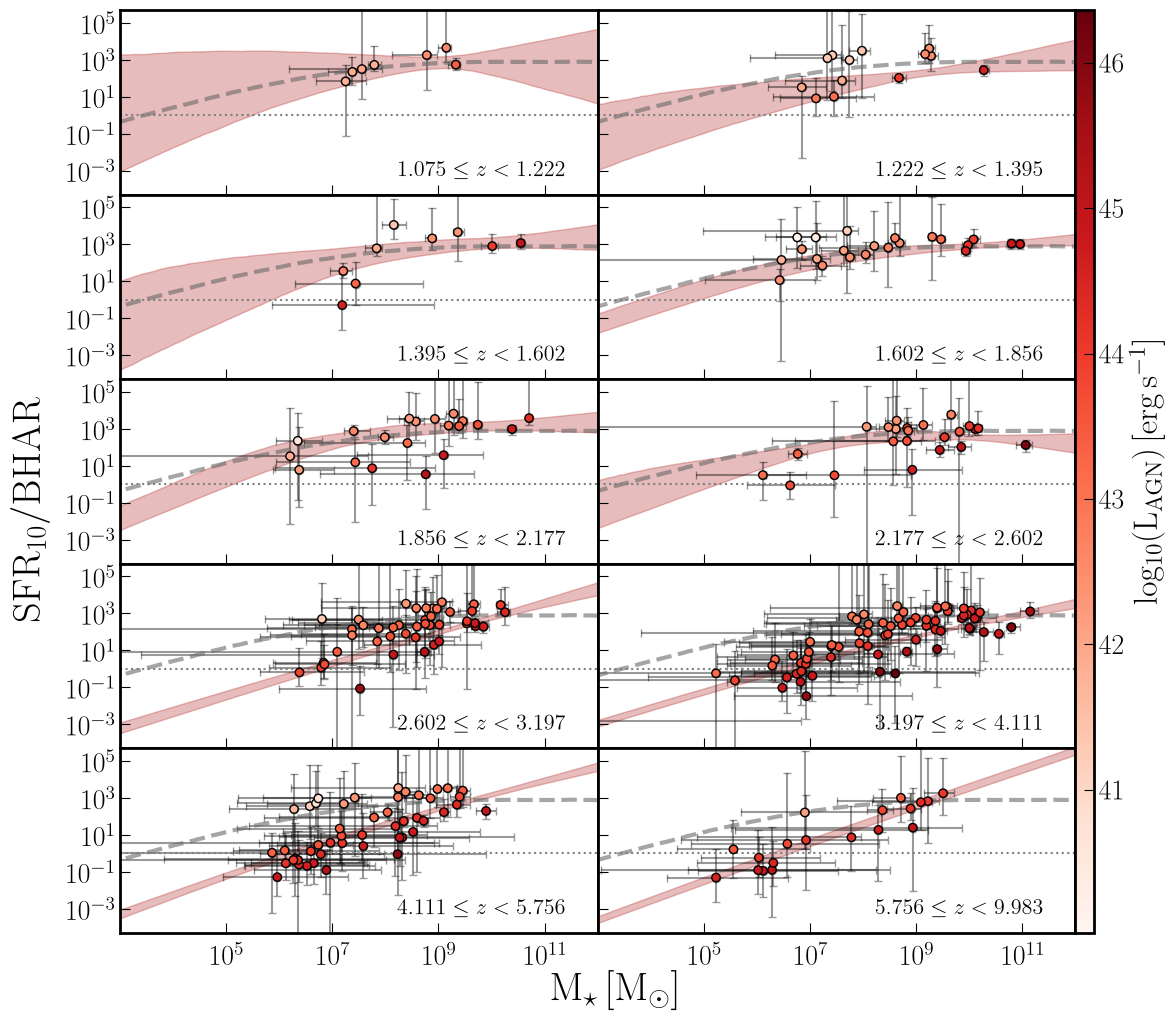

In [29]:
fig, ax = plt.subplots(5,2, figsize = (11,10), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0.0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1]) & (SMBH_results_sample["lowerlim"] == 0)

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["BHARSFR10Q50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [SMBH_results_sample["BHARSFR10_lo"][zidx], SMBH_results_sample["BHARSFR10_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )
    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["BHARSFR10Q50"][zidx],
        c = np.log10(prospect_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 1.0
    )

    # get LRD idx
    # ids = prospect_sample["CATID"][zidx] - 1
    # mask = ~np.isnan(lrd_fritz["zQ50"][ids]).to_numpy()
    # ax[i].scatter(
    #     prospect_sample["StellarMassQ50"][zidx][mask],
    #     SMBH_results_sample["BHARSFR10Q50"][zidx][mask],
    #     marker="x",
    #     zorder=100,
    #     color='tab:purple',
    #     alpha=1.0,
    #     s = 10
    # )

    fit_ = ax[i].fill_between(
                10**sfr_bhar_dpl_fits[i]["x"],
                10**(sfr_bhar_dpl_fits[i]["Q16"]),
                10**(sfr_bhar_dpl_fits[i]["Q84"]),
                color = "firebrick",
                alpha = 0.3
            )

    fit_z1 = ax[i].plot(
                            10**sfr_bhar_dpl_fits[0]["x"],
                            10**(sfr_bhar_dpl_fits[0]["Q50"]),
                            ls = "--",
                            lw = 3,
                            color = "dimgrey",
                            alpha = 0.6
                        )

    ax[i].axhline(1, ls = ":", color = "grey")

    ax[i].text(
        0.58,
        0.1,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e3, 1e12])
    ax[i].set_ylim([5e-5, 5e5])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([1e-3, 1e-1, 1e1, 1e3, 1e5])

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{SFR_{10} / BHAR}$", x = -0.05)

fig.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/bhar_sfr-mstar-z.pdf", 
    # dpi = 240,
    bbox_inches="tight"
)

## Compute redshift evolution of SFR/BHAR fit parameters

In [ ]:
fig, ax = plt.subplots(2, 2, layout = "constrained", figsize = (12, 8))
ax = ax.flatten()

ax[0].errorbar(
    zmids+0.1,
    sfr_bhar_dpl_params["M0Q50"],
    xerr = (np.diff(zbins)*0.5),
    yerr = [
        sfr_bhar_dpl_params["M0_lo"],
        sfr_bhar_dpl_params["M0_hi"]
    ],
    fmt = "s",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "grey",
    ecolor = "grey",
    label = r"$\mathcal{M}_{0}$"
)
ax[0].errorbar(
    zmids[0:],
    sfr_bhar_dpl_params["MbreakQ50"][0:],
    xerr = (np.diff(zbins)*0.5)[0:],
    yerr = [
        sfr_bhar_dpl_params["Mbreak_lo"][0:],
        sfr_bhar_dpl_params["Mbreak_hi"][0:]
    ],
    fmt = "o",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black",
    label = r"$\mathcal{M}_{\mathrm{SFR/BHAR = 1}}$"
)
ax[0].legend(
    fancybox=True
)

ax[1].errorbar(
    zmids+0.1,
    sfr_bhar_dpl_params["S0Q50"] - np.log10(2),
    xerr = (np.diff(zbins)*0.5),
    yerr = [
        sfr_bhar_dpl_params["S0_lo"],
        sfr_bhar_dpl_params["S0_hi"]
    ],
    fmt = "o",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black"
)

ax[2].errorbar(
    zmids+0.1,
    sfr_bhar_dpl_params["alphaQ50"],
    xerr = (np.diff(zbins)*0.5),
    yerr = [
        sfr_bhar_dpl_params["alpha_lo"],
        sfr_bhar_dpl_params["alpha_hi"]
    ],
    fmt = "o",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black"
)

ax[3].errorbar(
    zmids+0.1,
    sfr_bhar_dpl_params["betaQ50"],
    xerr = (np.diff(zbins)*0.5),
    yerr = [
        sfr_bhar_dpl_params["beta_lo"],
        sfr_bhar_dpl_params["beta_hi"]
    ],
    fmt = "o",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black"
)

for axx in ax:
    axx.set_xlim([zbins[0]-0.5, zbins[-1]+0.5])

ax[0].set_ylim([0.5, 11])
ax[1].set_ylim([-1.6, 3.6])
ax[2].set_ylim([-0.15, 1.65])
ax[3].set_ylim([-1.45, 1.65])

ax[0].set_yticks([2,4,6,8,10])
ax[1].set_yticks([-1.0, 0.0, 1.0, 2.0, 3.0])
ax[2].set_yticks([0.0, 0.5, 1.0, 1.5])
ax[3].set_yticks([-1.0, 0.0, 1.0])

ax[0].set_ylabel(r"$\mathrm{ \mathcal{M} \, [\log_{10}(M_{\odot})] }$")
ax[1].set_ylabel(r"$\mathrm{ S_{0} - \log_{10}(2)}$")
ax[2].set_ylabel(r"$\mathrm{ \alpha }$")
ax[3].set_ylabel(r"$\mathrm{ \beta }$")

ax[0].set_xlabel("Redshift")
ax[1].set_xlabel("Redshift")
ax[2].set_xlabel("Redshift")
ax[3].set_xlabel("Redshift")

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/sfr-bhar_dpl_fit_params_evol.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

# Mstar vs. MBH

In [30]:
reinesvolonteri15 = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/reinesvolonteri15.csv")
greene20 = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/greene20.csv")
suh20 = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/suh20.csv")
suh20_data = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/suh20_data.csv")

mezcua2324 = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/mezcua2324.csv")

harikane23 = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/harikane23_merged.csv")
maiolino24 = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/maiolino24_smbh.csv")
maiolino24["z"] = np.array([4.6482, 5.5951, 5.26894, 4.40935, 4.68123,5.22943,5.87461, 5.17241, 6.76026, 10.6])

juodzbalis26 = pd.concat(
    [pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/juodzbalis26_agn_data_raw.csv"),
    pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/juodzbalis26_sed_fits_raw.csv")],
    axis=1
)

brooks26 = pd.DataFrame({
    "z" : np.array([3.63, 4.46, 4.42, 5.62, 5.78]),
    "logMBH" : np.array([5.73, 5.32, 5.43, 6.08, 5.16]),
    "logMBH_lo" : np.array([0.42, 0.43, 0.40, 0.53, 0.43]),
    "logMBH_hi" : np.array([0.42, 0.42, 0.40, 0.45, 0.41]),

    "logMstar" : np.array([7.84, 8.08, 8.46, 7.88, 8.56]),
    "logMstar_lo" : np.array([0.12, 0.14, 0.10, 0.18, 0.03]),
    "logMstar_hi" : np.array([0.12, 0.14, 0.10, 0.18, 0.03]),
})
brooks26.to_csv(
    "/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/brooks26.csv"
)


koss22 = ascii.read(
    "/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-Catalogues/koss22.txt",
    format = "mrt"
)

# colors = [
#     "#112E81",  # maiolino24 (yours)
#     "#4382DF",  # juodzbalis26 (yours)
#     "#2A1B6B",
#     "#6B4FC9",
#     "#9B7FE8",
#     "#1B6B8C",
#     "#1B8C6B",
#     "#2FA66B",
#     "#7FC97F",
#     "#0A1F52",
# ]

suh20_col = "#156A40"
mezcua2324_col = "#7FC97F" 
harikane23_col = "#1B6B8C"
maiolino24_col = "#112E81"
juodzbalis26_col = "#4382DF"
brooks26_col = "#6B4FC9"

greene20_col = "grey"
# greene20_col = "#AACCD6"
# rv15_col = "grey"

In [31]:
def slope_angle(ax, x0, y0, slope=1.0, frac=1e-3):
    """Angle (degrees) that a power-law y = k*x^slope makes on screen at (x0,y0)."""
    x1 = x0 * (1 + frac)
    y1 = y0 * (x1 / x0)**slope
    p0 = ax.transData.transform((x0, y0))
    p1 = ax.transData.transform((x1, y1))
    return np.degrees(np.arctan2(p1[1] - p0[1], p1[0] - p0[0]))

## Using PDFs

Average MBH/MStar = -3.523080989840453
Average MBH/MStar = -3.627412766280916
Average MBH/MStar = -3.788797184266323
Average MBH/MStar = -3.8228324796393864
Average MBH/MStar = -3.5755273704466872
Average MBH/MStar = -3.3452197537860324
Average MBH/MStar = -3.08805917466383
Average MBH/MStar = -3.01623779515483
Average MBH/MStar = -2.1776789435792714
Average MBH/MStar = -2.008054069849829
Maiolino24 MBH/MStar = nan
Juodzbalis26 MBH/MStar = nan
Maiolino24 MBH/MStar = nan
Juodzbalis26 MBH/MStar = nan
Maiolino24 MBH/MStar = nan
Juodzbalis26 MBH/MStar = nan
Maiolino24 MBH/MStar = nan
Juodzbalis26 MBH/MStar = nan
Maiolino24 MBH/MStar = nan
Juodzbalis26 MBH/MStar = nan
Maiolino24 MBH/MStar = nan
Juodzbalis26 MBH/MStar = nan
Maiolino24 MBH/MStar = nan
Juodzbalis26 MBH/MStar = nan
Maiolino24 MBH/MStar = nan
Juodzbalis26 MBH/MStar = -1.4599999999999995
Maiolino24 MBH/MStar = -1.0099999999999998
Juodzbalis26 MBH/MStar = -1.8000000000000007


/Users/jordan/miniconda3/envs/space/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/var/folders/hv/hlgm1wrj0g7gzmpy8zr94wnw0000gn/T/ipykernel_3993/3603365787.py:247: RuntimeWarning: All-NaN slice encountered
  np.nanmedian(


Maiolino24 MBH/MStar = -1.8249999999999997
Juodzbalis26 MBH/MStar = -0.7600000000000007


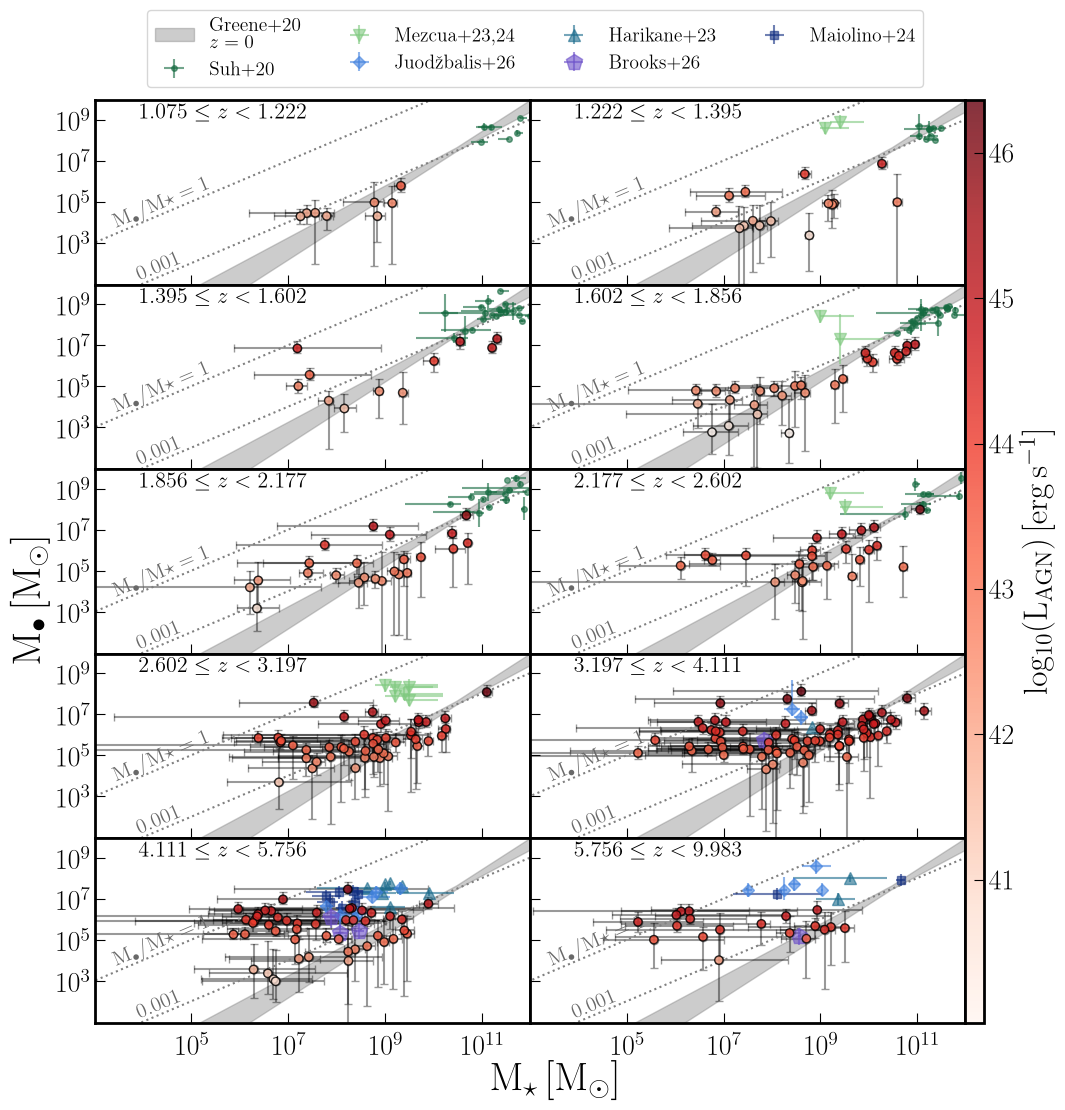

In [39]:
fig, ax = plt.subplots(5,2, figsize = (10,10), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1]) & (SMBH_results_sample["SMBHQ50"] != -999)

    print(
        f"Average MBH/MStar = {np.log10(np.median(SMBH_results_sample["SMBHQ50"][zidx]/prospect_sample["StellarMassQ50"][zidx]))}"
    )
 
    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["SMBHQ50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [SMBH_results_sample["SMBH_lo"][zidx], SMBH_results_sample["SMBH_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )
    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["SMBHQ50"][zidx],
        c = np.log10(prospect_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.8
    )

    ax[i].axhline(1, ls = ":", color = "grey")
    ax[i].plot(
        10**np.linspace(0,15,100),
        10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )
    ax[i].plot(
        10**np.linspace(0,15,100),
        1e-3 * 10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e3, 1e12])
    ax[i].set_ylim([9e0, 9e9])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])
    ax[i].set_yticks([1e3, 1e5, 1e7, 1e9])


cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{M_{\bullet} \, [M_{\odot}]}$", x = -0.045)

# --- NOW the layout is final, so draw and compute angles ---
fig.canvas.draw()

for i in range(len(zmids)):
    x0 = 3e3
    y0 = x0 
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        r"$\mathrm{M_{\bullet}/M\star} =  1$",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

    x0 = 9e3
    y0 = x0 * 1e-3
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        # r"$\mathrm{M_{\bullet}/M_{\star}}$",
        r"0.001",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

for i in range(len(zmids)):
    ax[i].fill_between(
        10**greene20["mstar"],
        10**greene20["smbh_lo"],
        10**greene20["smbh_hi"],
        color = greene20_col,
        alpha = 0.4,
        label = "Greene+20 \n $z=0$"
    )
    # ax[i].fill_between(
    #     10**reinesvolonteri15["mstar"],
    #     10**reinesvolonteri15["smbh_lo"],
    #     10**reinesvolonteri15["smbh_hi"],
    #     color = rv15_col,
    #     alpha = 0.4,
    #     label = "Reines \\& Volonteri 15 \n $z=0$"
    # )

    # if zmids[i] <= 2.5:
    #     ax[i].fill_between(
    #             10**suh20["mstar"],
    #             10**suh20["smbh_lo"],
    #             10**suh20["smbh_hi"],
    #             color = suh20_col,
    #             alpha = 0.2,
    #             label = "Suh+20 \n $z < 2.5$"
    #         )
    zidx = (suh20_data["z"] >= zbins[i]) & (suh20_data["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**suh20_data["logMstar"][zidx],
            10**suh20_data["logMBH"][zidx],
            xerr = [
                10**(suh20_data["logMstar"][zidx]) - 10**(suh20_data["logMstar"][zidx] - suh20_data["logMstar_lo"][zidx]),
                10**(suh20_data["logMstar"][zidx] + suh20_data["logMstar_hi"][zidx]) - 10**(suh20_data["logMstar"][zidx])
            ],
            yerr = [
                10**(suh20_data["logMBH"][zidx]) - 10**(suh20_data["logMBH"][zidx] - suh20_data["logMBH_err"][zidx]),
                10**(suh20_data["logMBH"][zidx] + suh20_data["logMBH_err"][zidx]) - 10**(suh20_data["logMBH"][zidx])
            ],
            marker = ".",
            markersize = 8,
            alpha = 0.6,
            color = suh20_col,
            ls = "",
            label = "Suh+20"
        )

    zidx = (mezcua2324["z"] >= zbins[i]) & (mezcua2324["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**mezcua2324["logMstar"][zidx],
            10**mezcua2324["logMBH"][zidx],
            xerr = [
                10**(mezcua2324["logMstar"][zidx]) - 10**(mezcua2324["logMstar"][zidx] - mezcua2324["logMstar_lo"][zidx]),
                10**(mezcua2324["logMstar"][zidx] + mezcua2324["logMstar_hi"][zidx]) - 10**(mezcua2324["logMstar"][zidx])
            ],
            yerr = [
                10**(mezcua2324["logMBH"][zidx]) - 10**(mezcua2324["logMBH"][zidx] - mezcua2324["logMBH_lo"][zidx]),
                10**(mezcua2324["logMBH"][zidx] + mezcua2324["logMBH_hi"][zidx]) - 10**(mezcua2324["logMBH"][zidx])
            ],
            marker = "v",
            markersize = 8,
            alpha = 0.6,
            color = mezcua2324_col,
            ls = "",
            label = "Mezcua+23,24"
        )

    zidx = (harikane23["z"] >= zbins[i]) & (harikane23["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**harikane23["logMstar"][zidx],
            harikane23["MBH"][zidx],
            xerr = [
                10**(harikane23["logMstar"][zidx]) - 10**(harikane23["logMstar"][zidx] - harikane23["logMstar_lo"][zidx]),
                10**(harikane23["logMstar"][zidx] + harikane23["logMstar_hi"][zidx]) - 10**(harikane23["logMstar"][zidx])
            ],
            yerr = [
                harikane23["MBH_lo"][zidx],
                harikane23["MBH_hi"][zidx]
            ],
            marker = "^",
            markersize = 8,
            alpha = 0.6,
            color = harikane23_col,
            ls = "",
            label = "Harikane+23"
        )

    zidx = (maiolino24["z"] >= zbins[i]) & (maiolino24["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**maiolino24["lg_Mstar"][zidx],
            10**maiolino24["lg_MBH"][zidx],
            xerr = [
                10**(maiolino24["lg_Mstar"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx] - maiolino24["lg_Mstar_err_lower"][zidx]),
                10**(maiolino24["lg_Mstar"][zidx] + maiolino24["lg_Mstar_err_upper"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx]),
            ],
            yerr = [
                10**(maiolino24["lg_MBH"][zidx]) - 10**(maiolino24["lg_MBH"][zidx] - maiolino24["lg_MBH_err_lower"][zidx]),
                10**(maiolino24["lg_MBH"][zidx] + maiolino24["lg_MBH_err_upper"][zidx]) - 10**(maiolino24["lg_MBH"][zidx]),
            ],
            marker = "s",
            color = maiolino24_col,
            alpha = 0.6,
            ls = "",
            label = "Maiolino+24"
        )
    print(
        f"Maiolino24 MBH/MStar = {
            np.nanmedian(
                maiolino24["lg_MBH"][zidx]-
                maiolino24["lg_Mstar"][zidx]
            )
        }"
    )

    zidx = (juodzbalis26["z"] >= zbins[i]) & (juodzbalis26["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**juodzbalis26["log_Mstar_FPHO"][zidx],
            10**juodzbalis26["log_MBH"][zidx],
            xerr = [
                10**(juodzbalis26["log_Mstar_FPHO"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx] - juodzbalis26["log_Mstar_FPHO_lo"][zidx]),
                10**(juodzbalis26["log_Mstar_FPHO"][zidx] + juodzbalis26["log_Mstar_FPHO_hi"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx])
            ],
            yerr = [
                10**(juodzbalis26["log_MBH"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx] - juodzbalis26["log_MBH_lo"][zidx]),
                10**(juodzbalis26["log_MBH"][zidx] + juodzbalis26["log_MBH_hi"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx])
            ],
            marker = "D",
            alpha = 0.6,
            color = juodzbalis26_col,
            ls = "",
            label = "Juodžbalis+26"
        )

    print(
        f"Juodzbalis26 MBH/MStar = {
            np.nanmedian(
                juodzbalis26["log_MBH"][zidx]-
                juodzbalis26["log_Mstar_FPHO"][zidx]
            )
        }"
    )
        
    zidx = (brooks26["z"] >= zbins[i]) & (brooks26["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**brooks26["logMstar"][zidx],
            10**brooks26["logMBH"][zidx],
            xerr = [
                10**(brooks26["logMstar"][zidx]) - 10**(brooks26["logMstar"][zidx] - brooks26["logMstar_lo"][zidx]),
                10**(brooks26["logMstar"][zidx] + brooks26["logMstar_hi"][zidx]) - 10**(brooks26["logMstar"][zidx])
            ],
            yerr = [
                10**(brooks26["logMBH"][zidx]) - 10**(brooks26["logMBH"][zidx] - brooks26["logMBH_lo"][zidx]),
                10**(brooks26["logMBH"][zidx] + brooks26["logMBH_hi"][zidx]) - 10**(brooks26["logMBH"][zidx])
            ],
            marker = "p",
            markersize = 12,
            alpha = 0.6,
            color = brooks26_col,
            ls = "",
            label = "Brooks+26"
        )

handles, labels = [], []
for ax in fig.axes:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

# optional: drop duplicate labels while preserving order
seen = dict(zip(labels, handles))
labels, handles = list(seen.keys()), list(seen.values())

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.48, 1.10),  # above the figure
    ncol = 4,
    # ncol=len(labels),            # optional: put all entries on one row
    fontsize=14,
    fancybox=True,
    frameon=True
)

fig.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/mstar-mbh-z.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

## M0=3

In [ ]:
fig, ax = plt.subplots(5,2, figsize = (10,10), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m03_SMBHQ50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [SMBH_results_sample["m03_SMBH_lo"][zidx], SMBH_results_sample["m03_SMBH_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )
    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m03_SMBHQ50"][zidx],
        c = np.log10(prospect_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.8
    )

    ax[i].axhline(1, ls = ":", color = "grey")
    ax[i].plot(
        10**np.linspace(0,15,100),
        10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )
    ax[i].plot(
        10**np.linspace(0,15,100),
        1e-3 * 10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e3, 1e12])
    ax[i].set_ylim([9e0, 9e9])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{M_{\bullet} \, [M_{\odot}]}$", x = -0.045)

# --- NOW the layout is final, so draw and compute angles ---
fig.canvas.draw()

for i in range(len(zmids)):
    x0 = 3e3
    y0 = x0 
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        r"$\mathrm{M_{\bullet}/M\star} =  1$",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

    x0 = 9e3
    y0 = x0 * 1e-3
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        # r"$\mathrm{M_{\bullet}/M_{\star}}$",
        r"0.001",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

for i in range(len(zmids)):
    ax[i].fill_between(
        10**greene20["mstar"],
        10**greene20["smbh_lo"],
        10**greene20["smbh_hi"],
        color = greene20_col,
        alpha = 0.4,
        label = "Greene+20 \n $z=0$"
    )
    # ax[i].fill_between(
    #     10**reinesvolonteri15["mstar"],
    #     10**reinesvolonteri15["smbh_lo"],
    #     10**reinesvolonteri15["smbh_hi"],
    #     color = rv15_col,
    #     alpha = 0.4,
    #     label = "Reines \\& Volonteri 15 \n $z=0$"
    # )

    # if zmids[i] <= 2.5:
    #     ax[i].fill_between(
    #             10**suh20["mstar"],
    #             10**suh20["smbh_lo"],
    #             10**suh20["smbh_hi"],
    #             color = suh20_col,
    #             alpha = 0.2,
    #             label = "Suh+20 \n $z < 2.5$"
    #         )
    zidx = (suh20_data["z"] >= zbins[i]) & (suh20_data["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**suh20_data["logMstar"][zidx],
            10**suh20_data["logMBH"][zidx],
            xerr = [
                10**(suh20_data["logMstar"][zidx]) - 10**(suh20_data["logMstar"][zidx] - suh20_data["logMstar_lo"][zidx]),
                10**(suh20_data["logMstar"][zidx] + suh20_data["logMstar_hi"][zidx]) - 10**(suh20_data["logMstar"][zidx])
            ],
            yerr = [
                10**(suh20_data["logMBH"][zidx]) - 10**(suh20_data["logMBH"][zidx] - suh20_data["logMBH_err"][zidx]),
                10**(suh20_data["logMBH"][zidx] + suh20_data["logMBH_err"][zidx]) - 10**(suh20_data["logMBH"][zidx])
            ],
            marker = ".",
            markersize = 8,
            alpha = 0.6,
            color = suh20_col,
            ls = "",
            label = "Suh+20"
        )

    zidx = (mezcua2324["z"] >= zbins[i]) & (mezcua2324["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**mezcua2324["logMstar"][zidx],
            10**mezcua2324["logMBH"][zidx],
            xerr = [
                10**(mezcua2324["logMstar"][zidx]) - 10**(mezcua2324["logMstar"][zidx] - mezcua2324["logMstar_lo"][zidx]),
                10**(mezcua2324["logMstar"][zidx] + mezcua2324["logMstar_hi"][zidx]) - 10**(mezcua2324["logMstar"][zidx])
            ],
            yerr = [
                10**(mezcua2324["logMBH"][zidx]) - 10**(mezcua2324["logMBH"][zidx] - mezcua2324["logMBH_lo"][zidx]),
                10**(mezcua2324["logMBH"][zidx] + mezcua2324["logMBH_hi"][zidx]) - 10**(mezcua2324["logMBH"][zidx])
            ],
            marker = "v",
            markersize = 8,
            alpha = 0.6,
            color = mezcua2324_col,
            ls = "",
            label = "Mezcua+23,24"
        )

    zidx = (harikane23["z"] >= zbins[i]) & (harikane23["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**harikane23["logMstar"][zidx],
            harikane23["MBH"][zidx],
            xerr = [
                10**(harikane23["logMstar"][zidx]) - 10**(harikane23["logMstar"][zidx] - harikane23["logMstar_lo"][zidx]),
                10**(harikane23["logMstar"][zidx] + harikane23["logMstar_hi"][zidx]) - 10**(harikane23["logMstar"][zidx])
            ],
            yerr = [
                harikane23["MBH_lo"][zidx],
                harikane23["MBH_hi"][zidx]
            ],
            marker = "^",
            markersize = 8,
            alpha = 0.6,
            color = harikane23_col,
            ls = "",
            label = "Harikane+23"
        )

    zidx = (maiolino24["z"] >= zbins[i]) & (maiolino24["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**maiolino24["lg_Mstar"][zidx],
            10**maiolino24["lg_MBH"][zidx],
            xerr = [
                10**(maiolino24["lg_Mstar"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx] - maiolino24["lg_Mstar_err_lower"][zidx]),
                10**(maiolino24["lg_Mstar"][zidx] + maiolino24["lg_Mstar_err_upper"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx]),
            ],
            yerr = [
                10**(maiolino24["lg_MBH"][zidx]) - 10**(maiolino24["lg_MBH"][zidx] - maiolino24["lg_MBH_err_lower"][zidx]),
                10**(maiolino24["lg_MBH"][zidx] + maiolino24["lg_MBH_err_upper"][zidx]) - 10**(maiolino24["lg_MBH"][zidx]),
            ],
            marker = "s",
            color = maiolino24_col,
            alpha = 0.6,
            ls = "",
            label = "Maiolino+24"
        )

    zidx = (juodzbalis26["z"] >= zbins[i]) & (juodzbalis26["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**juodzbalis26["log_Mstar_FPHO"][zidx],
            10**juodzbalis26["log_MBH"][zidx],
            xerr = [
                10**(juodzbalis26["log_Mstar_FPHO"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx] - juodzbalis26["log_Mstar_FPHO_lo"][zidx]),
                10**(juodzbalis26["log_Mstar_FPHO"][zidx] + juodzbalis26["log_Mstar_FPHO_hi"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx])
            ],
            yerr = [
                10**(juodzbalis26["log_MBH"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx] - juodzbalis26["log_MBH_lo"][zidx]),
                10**(juodzbalis26["log_MBH"][zidx] + juodzbalis26["log_MBH_hi"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx])
            ],
            marker = "D",
            alpha = 0.6,
            color = juodzbalis26_col,
            ls = "",
            label = "Juodžbalis+26"
        )

    zidx = (brooks26["z"] >= zbins[i]) & (brooks26["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**brooks26["logMstar"][zidx],
            10**brooks26["logMBH"][zidx],
            xerr = [
                10**(brooks26["logMstar"][zidx]) - 10**(brooks26["logMstar"][zidx] - brooks26["logMstar_lo"][zidx]),
                10**(brooks26["logMstar"][zidx] + brooks26["logMstar_hi"][zidx]) - 10**(brooks26["logMstar"][zidx])
            ],
            yerr = [
                10**(brooks26["logMBH"][zidx]) - 10**(brooks26["logMBH"][zidx] - brooks26["logMBH_lo"][zidx]),
                10**(brooks26["logMBH"][zidx] + brooks26["logMBH_hi"][zidx]) - 10**(brooks26["logMBH"][zidx])
            ],
            marker = "p",
            markersize = 12,
            alpha = 0.6,
            color = brooks26_col,
            ls = "",
            label = "Brooks+26"
        )

handles, labels = [], []
for ax in fig.axes:
    h, l = ax.get_legend_handles_labels()
    handles.extend(h)
    labels.extend(l)

# optional: drop duplicate labels while preserving order
seen = dict(zip(labels, handles))
labels, handles = list(seen.keys()), list(seen.values())

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.48, 1.12),  # above the figure
    ncol = 4,
    # ncol=len(labels),            # optional: put all entries on one row
    fontsize=14,
    fancybox=True,
    frameon=True
)

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/mstar-mbh-z_m03.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

## Mstar MBH, M0=2,4

In [ ]:
fig, ax = plt.subplots(5,2, figsize = (10,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m02_SMBHQ50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [SMBH_results_sample["m02_SMBH_lo"][zidx], SMBH_results_sample["m02_SMBH_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )
    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m02_SMBHQ50"][zidx],
        c = np.log10(prospect_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.8
    )

    ax[i].axhline(1, ls = ":", color = "grey")
    ax[i].plot(
        10**np.linspace(0,15,100),
        10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )
    ax[i].plot(
        10**np.linspace(0,15,100),
        1e-3 * 10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e3, 1e12])
    ax[i].set_ylim([9e0, 9e9])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{M_{\bullet} \, [M_{\odot}]}$", x = -0.045)

# --- NOW the layout is final, so draw and compute angles ---
fig.canvas.draw()

for i in range(len(zmids)):
    x0 = 3e3
    y0 = x0 
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        r"$\mathrm{M_{\bullet}/M\star} =  1$",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

    x0 = 9e3
    y0 = x0 * 1e-3
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        # r"$\mathrm{M_{\bullet}/M_{\star}}$",
        r"0.001",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

for i in range(len(zmids)):
    ax[i].fill_between(
        10**greene20["mstar"],
        10**greene20["smbh_lo"],
        10**greene20["smbh_hi"],
        color = greene20_col,
        alpha = 0.4,
        label = "Greene+20 \n $z=0$"
    )
    # ax[i].fill_between(
    #     10**reinesvolonteri15["mstar"],
    #     10**reinesvolonteri15["smbh_lo"],
    #     10**reinesvolonteri15["smbh_hi"],
    #     color = rv15_col,
    #     alpha = 0.4,
        # label = "Reines \\& Volonteri 15 \n $z=0$"
    # )

    zidx = (maiolino24["z"] >= zbins[i]) & (maiolino24["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**maiolino24["lg_Mstar"][zidx],
            10**maiolino24["lg_MBH"][zidx],
            xerr = [
                10**(maiolino24["lg_Mstar"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx] - maiolino24["lg_Mstar_err_lower"][zidx]),
                10**(maiolino24["lg_Mstar"][zidx] + maiolino24["lg_Mstar_err_upper"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx]),
            ],
            yerr = [
                10**(maiolino24["lg_MBH"][zidx]) - 10**(maiolino24["lg_MBH"][zidx] - maiolino24["lg_MBH_err_lower"][zidx]),
                10**(maiolino24["lg_MBH"][zidx] + maiolino24["lg_MBH_err_upper"][zidx]) - 10**(maiolino24["lg_MBH"][zidx]),
            ],
            marker = "s",
            color = maiolino24_col,
            alpha = 0.6,
            ls = "",
            label = "Maiolino+24"
        )

    zidx = (juodzbalis26["z"] >= zbins[i]) & (juodzbalis26["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**juodzbalis26["log_Mstar_FPHO"][zidx],
            10**juodzbalis26["log_MBH"][zidx],
            xerr = [
                10**(juodzbalis26["log_Mstar_FPHO"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx] - juodzbalis26["log_Mstar_FPHO_lo"][zidx]),
                10**(juodzbalis26["log_Mstar_FPHO"][zidx] + juodzbalis26["log_Mstar_FPHO_hi"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx])
            ],
            yerr = [
                10**(juodzbalis26["log_MBH"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx] - juodzbalis26["log_MBH_lo"][zidx]),
                10**(juodzbalis26["log_MBH"][zidx] + juodzbalis26["log_MBH_hi"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx])
            ],
            marker = "D",
            alpha = 0.6,
            color = juodzbalis26_col,
            ls = "",
            label = "Juodžbalis+26"
        )

handles, labels = ax[9].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.07),  # above the figure
    ncol=len(labels),            # optional: put all entries on one row
    fontsize=14,
    fancybox=True,
    frameon=True
)

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/mstar-mbh-z_m02.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

In [ ]:
fig, ax = plt.subplots(5,2, figsize = (10,12), sharex=True, sharey=True, layout='constrained')
fig.get_layout_engine().set(h_pad=0, w_pad=0.0, hspace=0, wspace=0)

ax = ax.flatten()

ztot_zidx = (prospect_robust["zQ50"] >= zbins[0]) & (prospect_robust["zQ50"] < zbins[-1])

for i in range(len(zmids)):
    zidx = (prospect_sample["zQ50"] >= zbins[i]) & (prospect_sample["zQ50"] < zbins[i+1])

    ax[i].errorbar(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m04_SMBHQ50"][zidx],
        xerr = [prospect_sample["StellarMass_lo"][zidx], prospect_sample["StellarMass_hi"][zidx]],
        yerr = [SMBH_results_sample["m04_SMBH_lo"][zidx], SMBH_results_sample["m04_SMBH_hi"][zidx]],
        fmt = "o",
        markerfacecolor = "grey",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        alpha = 0.4
    )
    sc_ = ax[i].scatter(
        prospect_sample["StellarMassQ50"][zidx],
        SMBH_results_sample["m04_SMBHQ50"][zidx],
        c = np.log10(prospect_sample["AGNlumQ50"][zidx]),
        edgecolor = "black",
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"][ztot_zidx])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.8
    )

    ax[i].axhline(1, ls = ":", color = "grey")
    ax[i].plot(
        10**np.linspace(0,15,100),
        10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )
    ax[i].plot(
        10**np.linspace(0,15,100),
        1e-3 * 10**np.linspace(0,15,100),
        ls = ":",
        color = "grey"
    )

    ax[i].text(
        0.1,
        0.9,
        rf"${zbins[i]:.3f} \leq z < {zbins[i+1]:.3f}$",
        transform=ax[i].transAxes,
        fontsize = 16
    )

    ax[i].set_xscale('log')
    ax[i].set_yscale('log')

    ax[i].set_xlim([1e3, 1e12])
    ax[i].set_ylim([9e0, 9e9])

    ax[i].set_xticks([1e5, 1e7, 1e9, 1e11])

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)

fig.supxlabel(r"$\mathrm{M_{\star} \, [M_{\odot}]}$")
fig.supylabel(r"$\mathrm{M_{\bullet} \, [M_{\odot}]}$", x = -0.045)

# --- NOW the layout is final, so draw and compute angles ---
fig.canvas.draw()

for i in range(len(zmids)):
    x0 = 3e3
    y0 = x0 
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        r"$\mathrm{M_{\bullet}/M\star} =  1$",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

    x0 = 9e3
    y0 = x0 * 1e-3
    angle = slope_angle(ax[i], x0, y0, slope=1.0)
    ax[i].text(
        x0, y0,
        # r"$\mathrm{M_{\bullet}/M_{\star}}$",
        r"0.001",
        rotation=angle,
        rotation_mode='anchor',
        ha='left', va='bottom',
        fontsize=15,
        color = "dimgrey"
    )

for i in range(len(zmids)):
    ax[i].fill_between(
        10**greene20["mstar"],
        10**greene20["smbh_lo"],
        10**greene20["smbh_hi"],
        color = greene20_col,
        alpha = 0.4,
        label = "Greene+20 \n $z=0$"
    )
    # ax[i].fill_between(
    #     10**reinesvolonteri15["mstar"],
    #     10**reinesvolonteri15["smbh_lo"],
    #     10**reinesvolonteri15["smbh_hi"],
    #     color = rv15_col,
    #     alpha = 0.4,
        # label = "Reines \\& Volonteri 15 \n $z=0$"
    # )

    zidx = (maiolino24["z"] >= zbins[i]) & (maiolino24["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**maiolino24["lg_Mstar"][zidx],
            10**maiolino24["lg_MBH"][zidx],
            xerr = [
                10**(maiolino24["lg_Mstar"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx] - maiolino24["lg_Mstar_err_lower"][zidx]),
                10**(maiolino24["lg_Mstar"][zidx] + maiolino24["lg_Mstar_err_upper"][zidx]) - 10**(maiolino24["lg_Mstar"][zidx]),
            ],
            yerr = [
                10**(maiolino24["lg_MBH"][zidx]) - 10**(maiolino24["lg_MBH"][zidx] - maiolino24["lg_MBH_err_lower"][zidx]),
                10**(maiolino24["lg_MBH"][zidx] + maiolino24["lg_MBH_err_upper"][zidx]) - 10**(maiolino24["lg_MBH"][zidx]),
            ],
            marker = "s",
            color = maiolino24_col,
            alpha = 0.6,
            ls = "",
            label = "Maiolino+24"
        )

    zidx = (juodzbalis26["z"] >= zbins[i]) & (juodzbalis26["z"] < zbins[i+1])
    if(sum(zidx) > 0):
        ax[i].errorbar(
            10**juodzbalis26["log_Mstar_FPHO"][zidx],
            10**juodzbalis26["log_MBH"][zidx],
            xerr = [
                10**(juodzbalis26["log_Mstar_FPHO"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx] - juodzbalis26["log_Mstar_FPHO_lo"][zidx]),
                10**(juodzbalis26["log_Mstar_FPHO"][zidx] + juodzbalis26["log_Mstar_FPHO_hi"][zidx]) - 10**(juodzbalis26["log_Mstar_FPHO"][zidx])
            ],
            yerr = [
                10**(juodzbalis26["log_MBH"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx] - juodzbalis26["log_MBH_lo"][zidx]),
                10**(juodzbalis26["log_MBH"][zidx] + juodzbalis26["log_MBH_hi"][zidx]) - 10**(juodzbalis26["log_MBH"][zidx])
            ],
            marker = "D",
            alpha = 0.6,
            color = juodzbalis26_col,
            ls = "",
            label = "Juodžbalis+26"
        )

handles, labels = ax[9].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.07),  # above the figure
    ncol=len(labels),            # optional: put all entries on one row
    fontsize=14,
    fancybox=True,
    frameon=True
)

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/mstar-mbh-z_m04.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

# Ledd histogram

In [48]:
ledd_bins = np.arange(np.log10(5e-6), np.log10(5e2) + 0.3, 0.3)

In [49]:
print(
    np.nanmin(SMBH_results_sample["LEddQ50"][SMBH_results_sample["LEddQ50"]>0])
)
print(
    np.nanmax(SMBH_results_sample["LEddQ50"])
)

0.131004881928868
3.6434609485836


In [ ]:
fig, ax = plt.subplots(1,1, figsize = (15,7), layout = 'constrained')

# --- main axes: scatter plots ---
sc_ = ax.scatter(
        prospect_sample["zQ50"],
        SMBH_results_sample["LEddQ50"],
        c = np.log10(prospect_sample["AGNlumQ50"]),
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.6
    )
ax.errorbar(
    prospect_sample["zQ50"],
    SMBH_results_sample["LEddQ50"],
    xerr = [prospect_sample["z_lo"], prospect_sample["z_hi"]],
    yerr = [SMBH_results_sample["LEdd_lo"],SMBH_results_sample["LEdd_hi"]],
    marker = "o",
    ls = "",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black",
    alpha = 0.2
)
sc_koss22_ = ax.scatter(
    koss22["z"],
    10**koss22["logEdd"],
    s = 10,
    marker = "s",
    zorder = 100, 
    c = "grey",
    alpha = 0.3
)
sc_harikane23_ = ax.errorbar(
    harikane23["z"],
    harikane23["Ledd"],
    yerr = [
        harikane23["Ledd_lo"],
        harikane23["Ledd_hi"]
    ],
    marker = "^",
    ls = "",
    alpha = 0.8,
    color = harikane23_col,
    label = "Harikane+23"
)
sc_maiolino24_ = ax.scatter(
    maiolino24["z"],
    maiolino24["L_LEdd"],
    marker = "s",
    alpha = 0.8,
    color = maiolino24_col,
    label = "Maiolino+24"
)
sc_juodzbalis26_ = ax.errorbar(
    juodzbalis26["z"],
    juodzbalis26["lambda_Edd"],
    yerr = [
        juodzbalis26["lambda_Edd_lo"],
        juodzbalis26["lambda_Edd_hi"]
    ],
    marker = "D",
    ls = "",
    alpha = 0.8,
    color = juodzbalis26_col,
    label = "Juodžbalis+26"
)
# sc_juodzbalis26_ = ax.scatter(
#     juodzbalis26["z"],
#     juodzbalis26["lambda_Edd"],
#     marker = "D",
#     alpha = 0.8,
#     color = juodzbalis26_col,
#     label = "Juodžbalis+26"
# )

ax.axhline(1.0, ls = ":", color = "grey")

ax.set_xlim([-0.25, zbins[-1]+0.5])
ax.set_yscale("log")
ax.set_ylim([5e-6, 5e2])
ax.set_ylabel(r"$\lambda_{\mathrm{Edd}}$", fontsize = 30)
ax.set_xlabel(r"Redshift", fontsize = 30)

# cax = inset_axes(
#     ax,
#     width="2%",
#     height="100%",
#     loc='lower left',
#     bbox_to_anchor=(1.0, 0., 1, 1),
#     bbox_transform=ax.transAxes,
#     borderpad=0,
# )

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 20)
# cbar.ax.yaxis.label.set_size(12)
# cbar.ax.tick_params(labelsize=12)

ax_top = ax.secondary_xaxis('top')
ax_top.set_xticks(ax.get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax.get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize = 20)

# --- inset axes: histogram ---
axin1 = ax.inset_axes([0.08, 0.15, 0.90, 0.28])

koss_counts, koss_bin_edges, koss_patches = axin1.hist(
    koss22["logEdd"], 
    color = "grey",
    alpha = 0.3,
    label = "Koss+22",
    bins = ledd_bins
)
ledd_counts, ledd_bin_edges, ledd_patches = axin1.hist(
    np.log10(SMBH_results_sample["LEddQ50"][SMBH_results_sample["LEddQ50"]>0]), 
    bins = ledd_bins,
    facecolor = "none",
    edgecolor = "black", 
    hatch = "\\\\", 
    lw = 2.0,
    label = "This work"
)

print(
    f"Median Koss+22 = {np.nanmedian(koss22["logEdd"])}"
)
print(
    f"Median our results = {np.nanmedian(np.log10(SMBH_results_sample["LEddQ50"][SMBH_results_sample["LEddQ50"]>0]))}"
)

print(
    f"Median our results z > 3 = {10**np.nanmedian(np.log10(SMBH_results_sample["LEddQ50"][(SMBH_results_sample["LEddQ50"]>0 ) & (prospect_sample["zQ50"] >= 3)]))}"
)
print(
    f"Median our results z < 3 = {10**np.nanmedian(np.log10(SMBH_results_sample["LEddQ50"][(SMBH_results_sample["LEddQ50"]>0 ) & (prospect_sample["zQ50"] <= 3)]))}"
)

axin1.set_yscale("log")
axin1.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: rf"$10^{{{x:g}}}$"))
axin1.patch.set_facecolor("none")
axin1.tick_params(axis='both', which='major', labelsize=18)
axin1.tick_params(axis='both', which='minor', labelsize=18)
axin1.set_xlabel(r"$\lambda_{\mathrm{Edd}}$", fontsize = 22, labelpad = 1)
axin1.set_ylabel("Frequency", fontsize = 20)
# axin1.xaxis.set_label_position('top') 
# axin1.xaxis.tick_top()
# axin1.tick_params(axis='x', which='major', tick1On=False, tick2On=False, pad=-1)

for spine in axin1.spines.values():
    spine.set_alpha(0.6)
    # spine.set_linewidth(1.0)  # optional: thinner too, if it still looks heavy

ax_handles, ax_labels = ax.get_legend_handles_labels()
axin1_handles, axin1_labels = axin1.get_legend_handles_labels()

ax.legend(
    handles=[(sc_, ledd_patches[0]), (sc_koss22_, koss_patches[0]), sc_harikane23_, sc_maiolino24_, sc_juodzbalis26_],
    labels = ["This work", "Koss+22", "Harikane+23", "Maiolino+24", "Juodžbalis+26"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=18,
    ncol = 3,
    loc="upper right",
    fancybox=True
)

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/ledd.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

In [ ]:
ledd_edges = 10**np.asarray(ledd_bins)            # linear edges for the log y-axis
logAGN     = np.log10(prospect_sample["AGNlumQ50"])
ledd_vals  = SMBH_results_sample["LEddQ50"][SMBH_results_sample["LEddQ50"] > 0]

# --- figure: histogram | main panel, shared y, no gap ---
fig, (axh, ax) = plt.subplots(
    1, 2, figsize=(14, 7), sharey=True,
    gridspec_kw=dict(width_ratios=[1, 7], wspace=0.0),
)
fig.get_layout_engine().set(h_pad=0, w_pad=-1.3, hspace=0, wspace=0)

# --- histogram first, so the legend handles exist ---
koss_counts, _, koss_patches = axh.hist(
    10**koss22["logEdd"], bins=ledd_edges, orientation="horizontal",
    color="grey", alpha=0.3,
)
ledd_counts, _, ledd_patches = axh.hist(
    ledd_vals, bins=ledd_edges, orientation="horizontal",
    facecolor="none", edgecolor="black", hatch="\\\\", lw=2.0,
)

# --- main panel ---
sc_ = ax.scatter(
    prospect_sample["zQ50"], SMBH_results_sample["LEddQ50"],
    c=logAGN, cmap="Reds", alpha=0.6, zorder=100,
)
ax.errorbar(
    prospect_sample["zQ50"], SMBH_results_sample["LEddQ50"],
    xerr=[prospect_sample["z_lo"], prospect_sample["z_hi"]],
    yerr=[SMBH_results_sample["LEdd_lo"], SMBH_results_sample["LEdd_hi"]],
    marker="o", ls="", capsize=3, markerfacecolor="none",
    markeredgecolor="black", ecolor="black", alpha=0.2,
)
sc_koss22_ = ax.scatter(
    koss22["z"], 10**koss22["logEdd"],
    s=10, marker="s", c="grey", alpha=0.3, zorder=100,
)
sc_harikane23_ = ax.errorbar(
    harikane23["z"], harikane23["Ledd"],
    yerr=[harikane23["Ledd_lo"], harikane23["Ledd_hi"]],
    marker="^", ls="", alpha=0.8, color=harikane23_col,
)
sc_maiolino24_ = ax.scatter(
    maiolino24["z"], maiolino24["L_LEdd"],
    marker="s", alpha=0.8, color=maiolino24_col,
)
sc_juodzbalis26_ = ax.errorbar(
    juodzbalis26["z"], juodzbalis26["lambda_Edd"],
    yerr=[juodzbalis26["lambda_Edd_lo"], juodzbalis26["lambda_Edd_hi"]],
    marker="D", ls="", alpha=0.8, color=juodzbalis26_col,
)

# --- axes limits, scales, labels (y settings propagate to axh via sharey) ---
ax.set_yscale("log")
ax.set_ylim(5e-6, 5e2)
ax.set_xlim(-0.25, zbins[-1] + 0.5)
ax.set_xlabel("Redshift", fontsize=30)
ax.axhline(1.0, ls=":", color="grey")

hmax = max(ledd_counts.max(), koss_counts.max())
axh.set_xscale("log")
axh.set_xlim(2 * hmax, 0.8)                        # reversed: bars grow leftward
axh.axhline(1.0, ls=":", color="grey")
axh.set_xlabel("Frequency", fontsize=25)
axh.set_ylabel(r"$\lambda_{\mathrm{Edd}}$", fontsize=30)
axh.tick_params(axis="both", which="major", labelsize=18)

# shared edge: labels/ticks/spine live on the histogram side only
# ax.tick_params(axis="y", left=False, labelleft=False)
# ax.spines["left"].set_visible(False)

# --- top axis: cosmic age, only for ticks inside the plotted range ---
lo, hi = ax.get_xlim()
zt = ax.get_xticks()
zt = zt[(zt >= max(lo, 0)) & (zt <= hi)]
ax_top = ax.secondary_xaxis("top")
ax_top.set_xticks(zt)
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(zt).value], fontsize=16)
ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize=20)

# --- colorbar: manual axes just right of the main panel ---
# pos = ax.get_position()
# cax = fig.add_axes([pos.x1 + 0.09, pos.y0+0.00565, 0.015, pos.height+0.021])
# fig.colorbar(sc_, cax=cax, label=r"$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$")
cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 20)


# --- legend ---
ax.legend(
    handles=[(sc_, ledd_patches[0]), (sc_koss22_, koss_patches[0]),
             sc_harikane23_, sc_maiolino24_, sc_juodzbalis26_],
    labels=["This work", "Koss+22", "Harikane+23", "Maiolino+24", "Juodžbalis+26"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=24, ncol=3, loc="lower right", fancybox=True,
)

fig.savefig("/Users/jordan/Documents/JWST-MIRI-AGN/plots/ledd.pdf", bbox_inches="tight", dpi = 240)

## M0=3

In [ ]:
fig, ax = plt.subplots(1,1, figsize = (11,8), layout = 'constrained')

# --- main axes: scatter plots ---
sc_ = ax.scatter(
        prospect_sample["zQ50"],
        SMBH_results_sample["m03_LEddQ50"],
        c = np.log10(prospect_sample["AGNlumQ50"]),
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.6
    )
ax.errorbar(
    prospect_sample["zQ50"],
    SMBH_results_sample["m03_LEddQ50"],
    xerr = [prospect_sample["z_lo"], prospect_sample["z_hi"]],
    yerr = [SMBH_results_sample["m03_LEdd_lo"],SMBH_results_sample["m03_LEdd_hi"]],
    marker = "o",
    ls = "",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black",
    alpha = 0.2
)
sc_koss22_ = ax.scatter(
    koss22["z"],
    10**koss22["logEdd"],
    s = 10,
    marker = "s",
    zorder = 100, 
    c = "grey",
    alpha = 0.3
)
sc_harikane23_ = ax.errorbar(
    harikane23["z"],
    harikane23["Ledd"],
    yerr = [
        harikane23["Ledd_lo"],
        harikane23["Ledd_hi"]
    ],
    marker = "^",
    ls = "",
    alpha = 0.8,
    color = harikane23_col,
    label = "Harikane+23"
)
sc_maiolino24_ = ax.scatter(
    maiolino24["z"],
    maiolino24["L_LEdd"],
    marker = "s",
    alpha = 0.8,
    color = maiolino24_col,
    label = "Maiolino+24"
)
sc_juodzbalis26_ = ax.errorbar(
    juodzbalis26["z"],
    juodzbalis26["lambda_Edd"],
    yerr = [
        juodzbalis26["lambda_Edd_lo"],
        juodzbalis26["lambda_Edd_hi"]
    ],
    marker = "D",
    ls = "",
    alpha = 0.8,
    color = juodzbalis26_col,
    label = "Juodžbalis+26"
)
# sc_juodzbalis26_ = ax.scatter(
#     juodzbalis26["z"],
#     juodzbalis26["lambda_Edd"],
#     marker = "D",
#     alpha = 0.8,
#     color = juodzbalis26_col,
#     label = "Juodžbalis+26"
# )
ax.axhline(1.0, ls = ":", color = "grey")

ax.set_xlim([-0.5, zbins[-1]+0.5])
ax.set_yscale("log")
ax.set_ylim([6e-7, 5e2])
ax.set_ylabel(r"$\lambda_{\mathrm{Edd}}$")
ax.set_xlabel(r"Redshift")

# cax = inset_axes(
#     ax,
#     width="2%",
#     height="100%",
#     loc='lower left',
#     bbox_to_anchor=(1.0, 0., 1, 1),
#     bbox_transform=ax.transAxes,
#     borderpad=0,
# )

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)
# cbar.ax.yaxis.label.set_size(12)
# cbar.ax.tick_params(labelsize=12)

ax_top = ax.secondary_xaxis('top')
ax_top.set_xticks(ax.get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax.get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

# --- inset axes: histogram ---
axin1 = ax.inset_axes([0.55, 0.1, 0.38, 0.44])

koss_counts, koss_bin_edges, koss_patches = axin1.hist(
    koss22["logEdd"], 
    color = "grey",
    alpha = 0.3,
    label = "Koss+22",
    bins = ledd_bins
)
ledd_counts, ledd_bin_edges, ledd_patches = axin1.hist(
    np.log10(SMBH_results_sample["m03_LEddQ50"][SMBH_results_sample["m03_LEddQ50"]>0]), 
    bins = ledd_bins,
    facecolor = "none",
    edgecolor = "black", 
    hatch = "\\\\", 
    lw = 2.0,
    label = "This work"
)

axin1.set_yscale("log")
axin1.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: rf"$10^{{{x:g}}}$"))
axin1.patch.set_facecolor("none")
axin1.tick_params(axis='both', which='major', labelsize=14)
axin1.tick_params(axis='both', which='minor', labelsize=14)
axin1.set_xlabel(r"$\lambda_{\mathrm{Edd}}$", fontsize = 16)
axin1.set_ylabel("Frequency", fontsize = 16)
for spine in axin1.spines.values():
    spine.set_alpha(0.6)
    # spine.set_linewidth(1.0)  # optional: thinner too, if it still looks heavy

ax_handles, ax_labels = ax.get_legend_handles_labels()
axin1_handles, axin1_labels = axin1.get_legend_handles_labels()

ax.legend(
    handles=[(sc_, ledd_patches[0]), (sc_koss22_, koss_patches[0]), sc_harikane23_, sc_maiolino24_, sc_juodzbalis26_],
    labels = ["This work", "Koss+22", "Harikane+23", "Maiolino+24", "Juodžbalis+26"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=16,
    ncol = 2,
    loc="upper right",
    fancybox=True
)

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/ledd_m03.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

## Ledd M0=2,4

In [ ]:
fig, ax = plt.subplots(1,1, figsize = (11,8), layout = 'constrained')

# --- main axes: scatter plots ---
sc_ = ax.scatter(
        prospect_sample["zQ50"],
        SMBH_results_sample["m02_LEddQ50"],
        c = np.log10(prospect_sample["AGNlumQ50"]),
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.6
    )
ax.errorbar(
    prospect_sample["zQ50"],
    SMBH_results_sample["m02_LEddQ50"],
    xerr = [prospect_sample["z_lo"], prospect_sample["z_hi"]],
    yerr = [SMBH_results_sample["m02_LEdd_lo"],SMBH_results_sample["m02_LEdd_hi"]],
    marker = "o",
    ls = "",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black",
    alpha = 0.2
)
sc_koss22_ = ax.scatter(
    koss22["z"],
    10**koss22["logEdd"],
    s = 10,
    marker = "s",
    zorder = 100, 
    c = "grey",
    alpha = 0.3
)
sc_maiolino24_ = ax.scatter(
    maiolino24["z"],
    maiolino24["L_LEdd"],
    marker = "s",
    alpha = 0.8,
    color = maiolino24_col,
    label = "Maiolino+24"
)
sc_juodzbalis26_ = ax.scatter(
    juodzbalis26["z"],
    juodzbalis26["lambda_Edd"],
    marker = "D",
    alpha = 0.8,
    color = juodzbalis26_col,
    label = "Juodžbalis+26"
)

ax.set_xlim([-0.5, zbins[-1]+0.5])
ax.set_yscale("log")
ax.set_ylim([9e-7, 2e2])
ax.set_ylabel(r"$\lambda_{\mathrm{Edd}}$")
ax.set_xlabel(r"Redshift")

# cax = inset_axes(
#     ax,
#     width="2%",
#     height="100%",
#     loc='lower left',
#     bbox_to_anchor=(1.0, 0., 1, 1),
#     bbox_transform=ax.transAxes,
#     borderpad=0,
# )

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)
# cbar.ax.yaxis.label.set_size(12)
# cbar.ax.tick_params(labelsize=12)

ax_top = ax.secondary_xaxis('top')
ax_top.set_xticks(ax.get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax.get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

# --- inset axes: histogram ---
axin1 = ax.inset_axes([0.55, 0.1, 0.38, 0.44])

koss_counts, koss_bin_edges, koss_patches = axin1.hist(
    koss22["logEdd"], 
    color = "grey",
    alpha = 0.3,
    label = "Koss+22"
)
ledd_counts, ledd_bin_edges, ledd_patches = axin1.hist(
    np.log10(SMBH_results_sample["m02_LEddQ50"][SMBH_results_sample["m02_LEddQ50"]>0]), 
    bins = koss_bin_edges,
    facecolor = "none",
    edgecolor = "black", 
    hatch = "\\\\", 
    lw = 2.0,
    label = "This work"
)

axin1.set_yscale("log")
axin1.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: rf"$10^{{{x:g}}}$"))
axin1.patch.set_facecolor("none")
axin1.tick_params(axis='both', which='major', labelsize=14)
axin1.tick_params(axis='both', which='minor', labelsize=14)
axin1.set_xlabel(r"$\lambda_{\mathrm{Edd}}$", fontsize = 16)
axin1.set_ylabel("Frequency", fontsize = 16)
for spine in axin1.spines.values():
    spine.set_alpha(0.6)
    # spine.set_linewidth(1.0)  # optional: thinner too, if it still looks heavy

ax_handles, ax_labels = ax.get_legend_handles_labels()
axin1_handles, axin1_labels = axin1.get_legend_handles_labels()

ax.legend(
    handles=[(sc_, ledd_patches[0]), (sc_koss22_, koss_patches[0]), sc_maiolino24_, sc_juodzbalis26_],
    labels = ["This work", "Koss+22", "Maiolino+24", "Juodžbalis+26"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=16,
    loc="best",
    fancybox=True
)

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/ledd_m02.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

In [ ]:
fig, ax = plt.subplots(1,1, figsize = (11,8), layout = 'constrained')

# --- main axes: scatter plots ---
sc_ = ax.scatter(
        prospect_sample["zQ50"],
        SMBH_results_sample["m04_LEddQ50"],
        c = np.log10(prospect_sample["AGNlumQ50"]),
        vmin = np.nanmin(np.log10(prospect_sample["AGNlumQ50"])),
        vmax = np.nanmax(np.log10(prospect_sample["AGNlumQ50"])),
        zorder = 100, 
        cmap='Reds',
        alpha = 0.6
    )
ax.errorbar(
    prospect_sample["zQ50"],
    SMBH_results_sample["m04_LEddQ50"],
    xerr = [prospect_sample["z_lo"], prospect_sample["z_hi"]],
    yerr = [SMBH_results_sample["m04_LEdd_lo"],SMBH_results_sample["m04_LEdd_hi"]],
    marker = "o",
    ls = "",
    capsize = 3,
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black",
    alpha = 0.2
)
sc_koss22_ = ax.scatter(
    koss22["z"],
    10**koss22["logEdd"],
    s = 10,
    marker = "s",
    zorder = 100, 
    c = "grey",
    alpha = 0.3
)
sc_maiolino24_ = ax.scatter(
    maiolino24["z"],
    maiolino24["L_LEdd"],
    marker = "s",
    alpha = 0.8,
    color = maiolino24_col,
    label = "Maiolino+24"
)
sc_juodzbalis26_ = ax.scatter(
    juodzbalis26["z"],
    juodzbalis26["lambda_Edd"],
    marker = "D",
    alpha = 0.8,
    color = juodzbalis26_col,
    label = "Juodžbalis+26"
)

ax.set_xlim([-0.5, zbins[-1]+0.5])
ax.set_yscale("log")
ax.set_ylim([9e-7, 2e2])

ax.set_ylabel(r"$\lambda_{\mathrm{Edd}}$")
ax.set_xlabel(r"Redshift")

# cax = inset_axes(
#     ax,
#     width="2%",
#     height="100%",
#     loc='lower left',
#     bbox_to_anchor=(1.0, 0., 1, 1),
#     bbox_transform=ax.transAxes,
#     borderpad=0,
# )

cbar = fig.colorbar(sc_, ax = ax, label=r'$\mathrm{log_{10}(L_{AGN}) \, [erg \, s^{-1}]}$', pad = 0.0, aspect = 50)
# cbar.ax.yaxis.label.set_size(12)
# cbar.ax.tick_params(labelsize=12)

ax_top = ax.secondary_xaxis('top')
ax_top.set_xticks(ax.get_xticks())
ax_top.set_xticklabels([f"{a:.2f}" for a in cosmo.age(ax.get_xticks()).value], fontsize = 16)
ax_top.set_xlabel("Time since the Big Bang [Gyr]", labelpad=8.0, fontsize = 16)

# --- inset axes: histogram ---
axin1 = ax.inset_axes([0.55, 0.1, 0.38, 0.44])

koss_counts, koss_bin_edges, koss_patches = axin1.hist(
    koss22["logEdd"], 
    color = "grey",
    alpha = 0.3,
    label = "Koss+22"
)
ledd_counts, ledd_bin_edges, ledd_patches = axin1.hist(
    np.log10(SMBH_results_sample["m04_LEddQ50"][SMBH_results_sample["m04_LEddQ50"]>0]), 
    bins = koss_bin_edges,
    facecolor = "none",
    edgecolor = "black", 
    hatch = "\\\\", 
    lw = 2.0,
    label = "This work"
)

axin1.set_yscale("log")
axin1.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: rf"$10^{{{x:g}}}$"))
axin1.patch.set_facecolor("none")
axin1.tick_params(axis='both', which='major', labelsize=14)
axin1.tick_params(axis='both', which='minor', labelsize=14)
axin1.set_xlabel(r"$\lambda_{\mathrm{Edd}}$", fontsize = 16)
axin1.set_ylabel("Frequency", fontsize = 16)
for spine in axin1.spines.values():
    spine.set_alpha(0.6)
    # spine.set_linewidth(1.0)  # optional: thinner too, if it still looks heavy

ax_handles, ax_labels = ax.get_legend_handles_labels()
axin1_handles, axin1_labels = axin1.get_legend_handles_labels()

ax.legend(
    handles=[(sc_, ledd_patches[0]), (sc_koss22_, koss_patches[0]), sc_maiolino24_, sc_juodzbalis26_],
    labels = ["This work", "Koss+22", "Maiolino+24", "Juodžbalis+26"],
    handler_map={tuple: HandlerTuple(ndivide=None)},
    fontsize=16,
    loc="best",
    fancybox=True
)

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/ledd_m04.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )

# Compare stuff between different M0

In [ ]:
fig, ax = plt.subplots(1,1, figsize = (7,5), layout = 'constrained')
ax = [ax]

ax[0].hist(
    np.log10(SMBH_results_sample["m02_SMBHQ50"][SMBH_results_sample["m02_SMBHQ50"]>0]/SMBH_results_sample["m05_SMBHQ50"][SMBH_results_sample["m05_SMBHQ50"]>0]),
    hatch = "\\\\",
    edgecolor = "#2E86AB",
    facecolor = lighten_color("#2E86AB", amount=0.5)
)
ax[0].hist(
    np.log10(SMBH_results_sample["m02_LEddQ50"][SMBH_results_sample["m02_LEddQ50"]>0]/SMBH_results_sample["m05_LEddQ50"][SMBH_results_sample["m05_LEddQ50"]>0]),
    hatch = "//",
    edgecolor = "#FF7F50",
    facecolor = lighten_color("#FF7F50", amount=0.5)
)

ax[0].set_xlim(-1.5,1.5)
# ax[1].set_xlim(-1.5,1.5)

ax[0].set_yscale("log")
# ax[1].set_yscale("log")

# --- Bottom axis (primary) ---
ax[0].set_xlabel(
    r"$\mathrm{ \log_{10}(M_{\bullet}^{M_{0}=10^{2} \, M_{\odot}}/ M_{\bullet}^{M_{0}=10^{5} \, M_{\odot} }) }$",
    color="#2E86AB"
)
ax[0].spines["bottom"].set_color(lighten_color("#2E86AB", 1.1))
ax[0].tick_params(axis="x", which="both", colors=lighten_color("#2E86AB", 1.1))

# --- Top axis (secondary) ---
ax_top = ax[0].secondary_xaxis('top')
ax_top.set_xlabel(
    r"$\mathrm{ \log_{10}(\lambda_{Edd}^{M_{0}=10^{2} \, M_{\odot}}/ \lambda_{Edd}^{M_{0}=10^{5} \, M_{\odot} }) }$",
    color="#FF7F50",
    labelpad=12
)
ax[0].spines["top"].set_color(lighten_color("#FF7F50", 1.1))
ax_top.spines["top"].set_color(lighten_color("#FF7F50", 1.1))
ax_top.tick_params(axis="x", which="both", colors=lighten_color("#FF7F50", 1.1))

ax[0].set_ylabel("Frequency")

# fig.savefig(
#     "/Users/jordan/Documents/JWST-MIRI-AGN/plots/compare_SMBH_LEdd_M02_M05.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )


# Alternative LRD models

In [50]:
from matplotlib.markers import MarkerStyle
from matplotlib.transforms import Affine2D

In [51]:
lrd_fritz = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/prospect/photoZ_bc03_snorm_fritz_norm_eazy_lrd_astro_cat.csv")
lrd_lrdmbb = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/prospect/photoZ_bc03_snorm_LRDMBB_norm_eazy_lrd_astro_cat.csv")

lrd_lit_fritz = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/lit_lrds_fritz_astro.csv")
lrd_lit_lrdmbb = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/lit_lrds_lrdmbb_astro.csv")

In [52]:
print(lrd_fritz.shape)

(30, 800)


In [53]:
fritz_color = "#D6247B"
lrdmbb_color = "#0E8C7D"
lrdliu_color = "#6A3DE8"
sirocco_color = "#E8622C"

spec_lw = 0.9
model_lw = 0.5
model_alpha = 0.2

In [54]:
print(
    f"Median AGNlum difference = {np.log10(np.nanmedian(lrd_fritz["AGNlumQ50"]/lrd_lrdmbb["AGNlumQ50"])):.5f} dex"
)

print(
    f"Median Mstar difference = {np.log10(np.nanmedian(lrd_fritz["StellarMassQ50"]/lrd_lrdmbb["StellarMassQ50"])):.5f} dex"
)

print(
    f"Median SFR10 difference = {np.log10(np.nanmedian(lrd_fritz["SFR10Q50"]/lrd_lrdmbb["SFR10Q50"])):.5f} dex"
)

print(
    f"Median UV difference = {(np.nanmedian(lrd_fritz["UV1500Q50"]-lrd_lrdmbb["UV1500Q50"])):.5f} dex"
)

Median AGNlum difference = 0.57133 dex
Median Mstar difference = 0.05781 dex
Median SFR10 difference = 0.05922 dex
Median UV difference = 0.09221 dex


In [55]:
print( lrd_fritz["ID"][(lrd_fritz["StellarMassQ50"]/lrd_lrdmbb["StellarMassQ50"]) > 10**2] )

print( lrd_fritz["ID"][(lrd_lrdmbb["StellarMassQ50"]/lrd_fritz["StellarMassQ50"]) > 10**2] )

12     806
15    1281
26    3444
Name: ID, dtype: int64
Series([], Name: ID, dtype: int64)


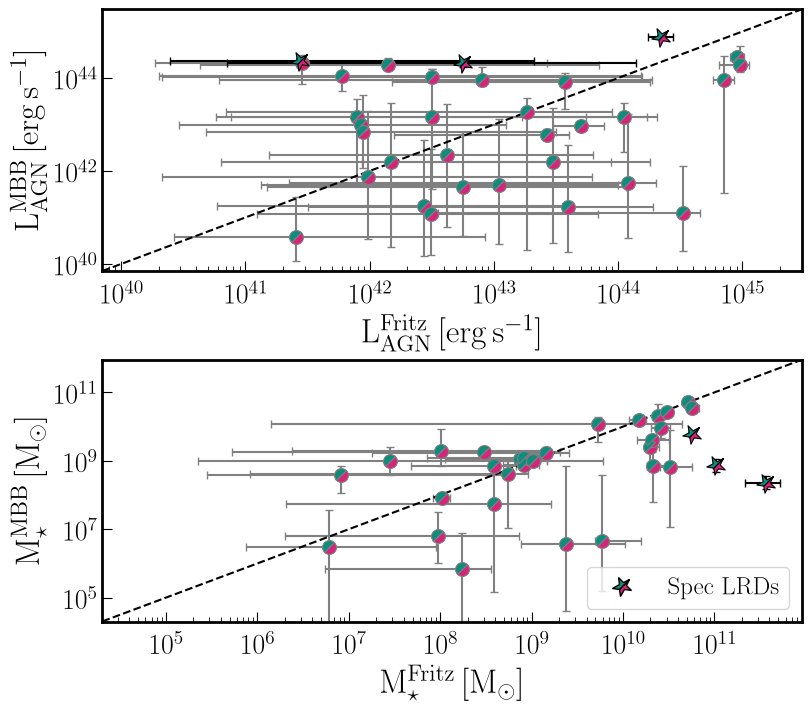

In [57]:
fig, ax = plt.subplots(2, 1, figsize = (8, 7), layout = "constrained")

diag_marker_a = MarkerStyle("o", fillstyle="right", transform=Affine2D().rotate_deg(-45))
diag_marker_b = MarkerStyle("o", fillstyle="left", transform=Affine2D().rotate_deg(-45))

diag_marker_star_a = MarkerStyle("*", fillstyle="right", transform=Affine2D().rotate_deg(-45))
diag_marker_star_b = MarkerStyle("*", fillstyle="left", transform=Affine2D().rotate_deg(-45))

ax[0].errorbar(
    lrd_fritz["AGNlumQ50"],
    lrd_lrdmbb["AGNlumQ50"],
    xerr=[lrd_fritz["AGNlum_lo"], lrd_fritz["AGNlum_hi"]],
    yerr=[lrd_lrdmbb["AGNlum_lo"], lrd_lrdmbb["AGNlum_hi"]],
    fmt="none",              # let marker be set separately below
    ecolor="grey",
    capsize=3
)
ax[0].scatter(
    lrd_fritz["AGNlumQ50"],
    lrd_lrdmbb["AGNlumQ50"],
    marker=diag_marker_a,
    s=100,
    facecolor=fritz_color,
    edgecolor="grey",
    linewidth=0.8,
    zorder = 200
)
ax[0].scatter(
    lrd_fritz["AGNlumQ50"],
    lrd_lrdmbb["AGNlumQ50"],
    marker=diag_marker_b,
    s=100,
    facecolor=lrdmbb_color,
    edgecolor="grey",
    linewidth=0.8,
    zorder = 200
)

ax[0].errorbar(
    lrd_lit_fritz["AGNlumQ50"],
    lrd_lit_lrdmbb["AGNlumQ50"],
    xerr=[lrd_lit_fritz["AGNlum_lo"], lrd_lit_fritz["AGNlum_hi"]],
    yerr=[lrd_lit_lrdmbb["AGNlum_lo"], lrd_lit_lrdmbb["AGNlum_hi"]],
    fmt="none",              # let marker be set separately below
    ecolor="black",
    capsize=3
)
ax[0].scatter(
    lrd_lit_fritz["AGNlumQ50"],
    lrd_lit_lrdmbb["AGNlumQ50"],
    marker=diag_marker_star_a,
    s=200,
    facecolor=fritz_color,
    edgecolor="black",
    linewidth=0.8,
    zorder = 200
)
ax[0].scatter(
    lrd_lit_fritz["AGNlumQ50"],
    lrd_lit_lrdmbb["AGNlumQ50"],
    marker=diag_marker_star_b,
    s=200,
    facecolor=lrdmbb_color,
    edgecolor="black",
    linewidth=0.8,
    zorder = 200
)

ax[0].plot(
    pow(10, np.arange(35.0, 49.0, 1)),
    pow(10, np.arange(35.0, 49.0, 1)),
    ls = "--",
    color = "black"
)

ax[0].set_xscale("log")
ax[0].set_yscale("log")

ax[0].set_xlim(7e39, 3e45)
ax[0].set_ylim(7e39, 3e45)

ax[0].set_xlabel(r"$\mathrm{L_{AGN}^{Fritz} \, [erg \, s^{-1}]}$")
ax[0].set_ylabel(r"$\mathrm{L_{AGN}^{MBB} \, [erg \, s^{-1}]}$")

ax[1].errorbar(
    lrd_fritz["StellarMassQ50"],
    lrd_lrdmbb["StellarMassQ50"],
    xerr=[lrd_fritz["StellarMass_lo"], lrd_fritz["StellarMass_hi"]],
    yerr=[lrd_lrdmbb["StellarMass_lo"], lrd_lrdmbb["StellarMass_hi"]],
    fmt="none",              # let marker be set separately below
    ecolor="grey",
    capsize=3
)
ax[1].scatter(
    lrd_fritz["StellarMassQ50"],
    lrd_lrdmbb["StellarMassQ50"],
    marker=diag_marker_a,
    s=100,
    facecolor=fritz_color,
    edgecolor="grey",
    linewidth=0.8,
    zorder = 230
)
ax[1].scatter(
    lrd_fritz["StellarMassQ50"],
    lrd_lrdmbb["StellarMassQ50"],
    marker=diag_marker_b,
    s=100,
    facecolor=lrdmbb_color,
    edgecolor="grey",
    linewidth=0.8,
    zorder = 230
)

ax[1].errorbar(
    lrd_lit_fritz["StellarMassQ50"],
    lrd_lit_lrdmbb["StellarMassQ50"],
    xerr=[lrd_lit_fritz["StellarMass_lo"], lrd_lit_fritz["StellarMass_hi"]],
    yerr=[lrd_lit_lrdmbb["StellarMass_lo"], lrd_lit_lrdmbb["StellarMass_hi"]],
    fmt="none",              # let marker be set separately below
    ecolor="black",
    capsize=3
)
ax[1].scatter(
    lrd_lit_fritz["StellarMassQ50"],
    lrd_lit_lrdmbb["StellarMassQ50"],
    marker=diag_marker_star_a,
    s=200,
    facecolor=fritz_color,
    edgecolor="black",
    linewidth=0.8,
    zorder = 230
)
ax[1].scatter(
    lrd_lit_fritz["StellarMassQ50"],
    lrd_lit_lrdmbb["StellarMassQ50"],
    marker=diag_marker_star_b,
    s=200,
    facecolor=lrdmbb_color,
    edgecolor="black",
    linewidth=0.8,
    zorder = 230
)

legend_proxy = Line2D(
    [0], [0],
    marker=diag_marker_star_a,
    markersize=14,
    markerfacecolor=fritz_color,
    markerfacecoloralt=lrdmbb_color,   # Line2D DOES support this, unlike scatter
    markeredgecolor="black",
    linestyle="none",
    label="Spec LRDs"
)

ax[1].legend(
    handles=[legend_proxy], 
    fontsize = 18,
    loc = "lower right"
)
# ax[1].legend(
#     fontsize = 18,
#     loc = "lower right"
# )

ax[1].plot(
    pow(10, np.arange(1.0, 13.0, 1)),
    pow(10, np.arange(1.0, 13.0, 1)),
    ls = "--",
    color = "black"
)

ax[1].set_xscale("log")
ax[1].set_yscale("log")

ax[1].set_xlim(2e4, 9e11)
ax[1].set_ylim(2e4, 9e11)

ax[1].set_xlabel(r"$\mathrm{M_{\star}^{Fritz} \, [M_{\odot}]}$")
ax[1].set_ylabel(r"$\mathrm{M_{\star}^{MBB} \, [M_{\odot}]}$")

fig.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/LRD_quantities_compare.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

## Show SEDs of lit LRDs

In [ ]:
akins25 = pd.read_csv("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature/AGN-seds/akins25_stack.csv")

In [ ]:
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/spec/rubies-uds31-v4_prism-clear_4233_154183.spec.fits") as f:
    cliff_spec = pd.DataFrame({
        "wave" : f["SPEC1D"].data["wave"],
        "flux" : f["SPEC1D"].data["flux"],
        "err" : f["SPEC1D"].data["err"]
    })

with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/spec/mom-uds01-v4_prism-clear_5224_150135.spec.fits") as f:
    mombh1_spec = pd.DataFrame({
        "wave" : f["SPEC1D"].data["wave"],
        "flux" : f["SPEC1D"].data["flux"],
        "err" : f["SPEC1D"].data["err"]
    })

with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/spec/jades-gdn2-v4_prism-clear_1181_28074.spec.fits") as f:
    rosetta_spec = pd.DataFrame({
        "wave" : f["SPEC1D"].data["wave"],
        "flux" : f["SPEC1D"].data["flux"],
        "err" : f["SPEC1D"].data["err"]
    })

In [ ]:
cliff_redshift = 3.55
mombh1_redshift = 7.7569
rosetta_redshift = 2.26

In [ ]:
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Cliff_fritz_sed.fits") as f:
    cliff_fritz_obs_fit = pd.DataFrame(f["obs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Cliff_lrdliu_sed.fits") as f:
    cliff_lrdliu_obs_fit = pd.DataFrame(f["obs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Cliff_lrdmbb_sed.fits") as f:
    cliff_lrdmbb_obs_fit = pd.DataFrame(f["obs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Cliff_sirocco_sed.fits") as f:
    cliff_sirocco_obs_fit = pd.DataFrame(f["obs"].data)

with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/MoMBH1_fritz_sed.fits") as f:
    mombh1_fritz_obs_fit = pd.DataFrame(f["obs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/MoMBH1_lrdliu_sed.fits") as f:
    mombh1_lrdliu_obs_fit = pd.DataFrame(f["obs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/MoMBH1_lrdmbb_sed.fits") as f:
    mombh1_lrdmbb_obs_fit = pd.DataFrame(f["obs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/MoMBH1_sirocco_sed.fits") as f:
    mombh1_sirocco_obs_fit = pd.DataFrame(f["obs"].data)

with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Rosetta_fritz_sed.fits") as f:
    rosetta_fritz_obs_fit = pd.DataFrame(f["obs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Rosetta_lrdliu_sed.fits") as f:
    rosetta_lrdliu_obs_fit = pd.DataFrame(f["obs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Rosetta_lrdmbb_sed.fits") as f:
    rosetta_lrdmbb_obs_fit = pd.DataFrame(f["obs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Rosetta_sirocco_sed.fits") as f:
    rosetta_sirocco_obs_fit = pd.DataFrame(f["obs"].data)

with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Cliff_fritz_sed.fits") as f:
    cliff_fritz_AGN_fit = pd.DataFrame(f["AGNobs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Cliff_lrdliu_sed.fits") as f:
    cliff_lrdliu_AGN_fit = pd.DataFrame(f["AGNobs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Cliff_lrdmbb_sed.fits") as f:
    cliff_lrdmbb_AGN_fit = pd.DataFrame(f["AGNobs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Cliff_sirocco_sed.fits") as f:
    cliff_sirocco_AGN_fit = pd.DataFrame(f["AGNobs"].data)

with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/MoMBH1_fritz_sed.fits") as f:
    mombh1_fritz_AGN_fit = pd.DataFrame(f["AGNobs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/MoMBH1_lrdliu_sed.fits") as f:
    mombh1_lrdliu_AGN_fit = pd.DataFrame(f["AGNobs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/MoMBH1_lrdmbb_sed.fits") as f:
    mombh1_lrdmbb_AGN_fit = pd.DataFrame(f["AGNobs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/MoMBH1_sirocco_sed.fits") as f:
    mombh1_sirocco_AGN_fit = pd.DataFrame(f["AGNobs"].data)

with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Rosetta_fritz_sed.fits") as f:
    rosetta_fritz_AGN_fit = pd.DataFrame(f["AGNobs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Rosetta_lrdliu_sed.fits") as f:
    rosetta_lrdliu_AGN_fit = pd.DataFrame(f["AGNobs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Rosetta_lrdmbb_sed.fits") as f:
    rosetta_lrdmbb_AGN_fit = pd.DataFrame(f["AGNobs"].data)
with fits.open("/Users/jordan/Documents/JWST-MIRI-AGN/data/literature_lrds/Rosetta_sirocco_sed.fits") as f:
    rosetta_sirocco_AGN_fit = pd.DataFrame(f["AGNobs"].data)

In [ ]:
fig, ax = plt.subplots(3, 2, figsize = (12, 8), layout = "constrained", sharex = False, sharey=False)
ax = ax.flatten()

print("Check flux_scale")

ax[0].scatter(
    akins25["Wavelength_um"][-12:],
    akins25["F_nu"][-12:] * 1e6,
    marker = down_arrow_marker,
    s = 550,
    color = "grey"
)
for i in [0,1]:
    ax[i].plot(
        mombh1_spec["wave"],
        mombh1_spec["flux"] * 0.7288428,
        color = "black",
        lw = spec_lw,
    )
    ax[i].errorbar(
        np.array([76128.766, 180396.821])/1e4,
        np.array([465, 1269]) * 1e-3,
        yerr = [np.array([52, 615]) * 1e-3],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        markersize = 12
    )
    ax[i].fill_between(
        mombh1_lrdmbb_obs_fit["obswave"]/1e4,
        mombh1_lrdmbb_obs_fit["fluxQ16"] * 1e6,
        mombh1_lrdmbb_obs_fit["fluxQ84"] * 1e6,
        color = lrdmbb_color,
        alpha = model_alpha,
        label = "MBB"
    )
    ax[i].fill_between(
        mombh1_lrdliu_obs_fit["obswave"]/1e4,
        mombh1_lrdliu_obs_fit["fluxQ16"] * 1e6,
        mombh1_lrdliu_obs_fit["fluxQ84"] * 1e6,
        color = lrdliu_color,
        alpha = model_alpha,
        label = "Liu+26"
    )
    ax[i].fill_between(
        mombh1_sirocco_obs_fit["obswave"]/1e4,
        mombh1_sirocco_obs_fit["fluxQ16"] * 1e6,
        mombh1_sirocco_obs_fit["fluxQ84"] * 1e6,
        color = sirocco_color,
        alpha = model_alpha,
        label = "Sneppen+26"
    )
    ax[i].fill_between(
        mombh1_fritz_obs_fit["obswave"]/1e4,
        mombh1_fritz_obs_fit["fluxQ16"] * 1e6,
        mombh1_fritz_obs_fit["fluxQ84"] * 1e6,
        color = fritz_color,
        alpha = model_alpha,
        label = "Fritz+06"
    )
    # ax[i].set_xscale("log")
    ax[i].set_yscale("log")
ax[0].set_xscale("log")
ax[0].set_ylabel(r"$f_{\nu} \, \mathrm{[\mu Jy]}$")
ax[0].text(
    0.05, 
    0.8, 
    r"$\mathrm{MoM-BH^{*}-1}$",
    transform = ax[0].transAxes
)
ax[1].legend(
    fontsize = 14,
    loc = "lower right",
    ncol = 1
)

ax[2].scatter(
    akins25["Wavelength_um"][-12:],
    akins25["F_nu"][-12:] * 1e6,
    marker = down_arrow_marker,
    s = 550,
    color = "grey",
    label = "Akins+25 \n Upper limits"
)
for i in [2,3]:
    ax[i].plot(
        cliff_spec["wave"],
        cliff_spec["flux"] * 1.144094, 
        color = "black",
        lw = spec_lw,
        label = "NIRSpec"
    )
    ax[i].errorbar(
        np.array([76128.766, 180396.821])/1e4,
        np.array([1.54, 1.96]),
        yerr = [np.array([0.03, 0.5]), np.array([0.03, 0.5])],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "black",
        ecolor = "black",
        capsize = 3,
        markersize = 12,
        label = "MIRI"
    )
    ax[i].fill_between(
        cliff_lrdmbb_obs_fit["obswave"]/1e4,
        cliff_lrdmbb_obs_fit["fluxQ16"] * 1e6,
        cliff_lrdmbb_obs_fit["fluxQ84"] * 1e6,
        color = lrdmbb_color,
        alpha = model_alpha
    )
    ax[i].fill_between(
        cliff_lrdliu_obs_fit["obswave"]/1e4,
        cliff_lrdliu_obs_fit["fluxQ16"] * 1e6,
        cliff_lrdliu_obs_fit["fluxQ84"] * 1e6,
        color = lrdliu_color,
        alpha = model_alpha
    )
    ax[i].fill_between(
        cliff_sirocco_obs_fit["obswave"]/1e4,
        cliff_sirocco_obs_fit["fluxQ16"] * 1e6,
        cliff_sirocco_obs_fit["fluxQ84"] * 1e6,
        color = sirocco_color,
        alpha = model_alpha
    )
    ax[i].fill_between(
        cliff_fritz_obs_fit["obswave"]/1e4,
        cliff_fritz_obs_fit["fluxQ16"] * 1e6,
        cliff_fritz_obs_fit["fluxQ84"] * 1e6,
        color = fritz_color,
        alpha = model_alpha
    )
    # ax[i].set_xscale("log")
    ax[i].set_yscale("log")
ax[2].set_xscale("log")
ax[2].set_ylabel(r"$f_{\nu} \, \mathrm{[\mu Jy]}$")
ax[2].text(
    0.05, 
    0.8, 
    r"$\mathrm{The \; Cliff}$",
    transform = ax[2].transAxes
)
ax[2].legend(
    fontsize = 14,
    loc = "lower right"
)

ax[4].scatter(
    akins25["Wavelength_um"][-12:],
    akins25["F_nu"][-12:] * 1e6,
    marker = down_arrow_marker,
    s = 550,
    color = "grey"
)
for i in [4,5]:
    ax[i].plot(
        rosetta_spec["wave"],
        rosetta_spec["flux"] * 1.259779,
        color = "black",
        lw = spec_lw,
    )
    ax[i].errorbar(
        np.array([56820.10, 77546.05, 235124.42])/1e4,
        np.array([10.59254, 12.79263, 43.03500]),
        yerr = [np.array([0.64976, 1.28429, 6.88580])],
        fmt = "o",
        markerfacecolor = "none",
        markeredgecolor = "maroon",
        ecolor = "maroon",
        capsize = 3,
        markersize = 12,
        label = "Spitzer"
    )
    ax[i].fill_between(
        rosetta_lrdmbb_obs_fit["obswave"]/1e4,
        rosetta_lrdmbb_obs_fit["fluxQ16"] * 1e6,
        rosetta_lrdmbb_obs_fit["fluxQ84"] * 1e6,
        color = lrdmbb_color,
        alpha = model_alpha
    )
    ax[i].fill_between(
        rosetta_lrdliu_obs_fit["obswave"]/1e4,
        rosetta_lrdliu_obs_fit["fluxQ16"] * 1e6,
        rosetta_lrdliu_obs_fit["fluxQ84"] * 1e6,
        color = lrdliu_color,
        alpha = model_alpha
    )
    ax[i].fill_between(
        rosetta_sirocco_obs_fit["obswave"]/1e4,
        rosetta_sirocco_obs_fit["fluxQ16"] * 1e6,
        rosetta_sirocco_obs_fit["fluxQ84"] * 1e6,
        color = sirocco_color,
        alpha = model_alpha
    )
    ax[i].fill_between(
        rosetta_fritz_obs_fit["obswave"]/1e4,
        rosetta_fritz_obs_fit["fluxQ16"] * 1e6,
        rosetta_fritz_obs_fit["fluxQ84"] * 1e6,
        color = fritz_color,
        alpha = model_alpha
    )
    # ax[i].set_xscale("log")
    ax[i].set_yscale("log")
ax[4].set_xscale("log")
ax[4].set_ylabel(r"$f_{\nu} \, \mathrm{[\mu Jy]}$")
ax[4].text(
    0.05, 
    0.8, 
    r"$\mathrm{Rosetta \; Stone}$",
    transform = ax[4].transAxes
)
ax[4].legend(
    fontsize = 14,
    loc = "lower right"
)

spines_color = "dimgrey"
for i in [0,2,4]:
    ax[i].set_xlim([0.5, 3e3])
    ax[i].set_ylim([8e-4, 1e4])

xright = 5.1
for i in [1,3,5]:
    ax[i].set_xlim([0.8, xright])
    ax[i].spines["bottom"].set_color(spines_color)
    ax[i].spines["left"].set_color(spines_color)
    ax[i].spines["top"].set_color(spines_color)
    ax[i].spines["right"].set_color(spines_color)

    ax[i].spines["bottom"].set_linestyle("dashed")
    ax[i].spines["left"].set_linestyle("dashed")
    ax[i].spines["top"].set_linestyle("dashed")
    ax[i].spines["right"].set_linestyle("dashed")
    ax[i].tick_params(axis="both", colors = spines_color)
ax[1].set_ylim([7e-4, 9e-1])
ax[3].set_ylim([7e-3, 9e0])
ax[5].set_ylim([7e-2, 9e1])

rect1 = Patches.Rectangle((0.8, 13e-4), xright-0.8, (9e-1), facecolor = "none", edgecolor = spines_color, lw = 1, alpha = 0.8, ls = "--")
ax[0].add_patch(rect1)
rect2 = Patches.Rectangle((0.8, 7e-3), xright-0.8, (9e0), facecolor = "none", edgecolor = spines_color, lw = 1, alpha = 0.8, ls = "--")
ax[2].add_patch(rect2)
rect4 = Patches.Rectangle((0.8, 7e-2), xright-0.8, (9e1), facecolor = "none", edgecolor = spines_color, lw = 1, alpha = 0.8, ls = "--")
ax[4].add_patch(rect4)

fig.supxlabel("Wavelength [$\\mu$m]")

fig.savefig(
    "/Users/jordan/Documents/JWST-MIRI-AGN/plots/LRD_literature_fits.pdf", 
    dpi = 240,
    bbox_inches="tight"
)

In [ ]:
fig, ax = plt.subplots(1, 1, figsize = (10,7))
nirspec_, = ax.plot(
        cliff_spec["wave"],
        cliff_spec["flux"] * 1.144094, 
        color = "black",
        lw = spec_lw,
        label = "NIRSpec"
    )
miri_ = ax.errorbar(
    np.array([76128.766, 180396.821])/1e4,
    np.array([1.54, 1.96]),
    yerr = [np.array([0.03, 0.5]), np.array([0.03, 0.5])],
    fmt = "o",
    markerfacecolor = "none",
    markeredgecolor = "black",
    ecolor = "black",
    capsize = 3,
    markersize = 12,
    label = "MIRI"
)
mbb_ = ax.fill_between(
    cliff_lrdmbb_obs_fit["obswave"]/1e4,
    cliff_lrdmbb_obs_fit["fluxQ16"] * 1e6,
    cliff_lrdmbb_obs_fit["fluxQ84"] * 1e6,
    color = lrdmbb_color,
    alpha = model_alpha,
    label = "Modified blackbody"
)
liu_ = ax.fill_between(
    cliff_lrdliu_obs_fit["obswave"]/1e4,
    cliff_lrdliu_obs_fit["fluxQ16"] * 1e6,
    cliff_lrdliu_obs_fit["fluxQ84"] * 1e6,
    color = lrdliu_color,
    alpha = model_alpha,
    label = "Liu+26 photosphere"
)
# sirocco_ = ax.fill_between(
#     cliff_sirocco_obs_fit["obswave"]/1e4 * 1.01,
#     cliff_sirocco_obs_fit["fluxQ16"] * 1e6,
#     cliff_sirocco_obs_fit["fluxQ84"] * 1e6,
#     color = sirocco_color,
#     alpha = model_alpha,
#     label = "Sneppen+26 ionised cocoon"
# )
fritz_ = ax.fill_between(
    cliff_fritz_obs_fit["obswave"]/1e4,
    cliff_fritz_obs_fit["fluxQ16"] * 1e6,
    cliff_fritz_obs_fit["fluxQ84"] * 1e6,
    color = fritz_color,
    alpha = model_alpha,
    label = "Fritz+06 dusty torus"
)

ax.set_xlim([0.8, 5.1])
ax.set_ylim([7e-3, 9e0])

ax.set_yscale("log")

ax.legend(
    handles=(nirspec_, fritz_, mbb_, liu_),
    fontsize = 20,
    loc = "lower right",
    ncol = 2
)

ax.text(
    0.05, 
    0.8, 
    r"$\mathrm{The \; Cliff}$",
    transform = ax.transAxes
)
ax.text(
    0.05, 
    0.6, 
    r"$z_{\mathrm{spec}} = 3.55$",
    transform = ax.transAxes
)

ax.set_ylabel(r"$f_{\nu} \, \mathrm{[\mu Jy]}$")
ax.set_xlabel("Wavelength [$\\mu$m]")

# fig.savefig(
#     "/Users/jordan/Documents/JD_CV/figures/cliff_sed.pdf", 
#     dpi = 240,
#     bbox_inches="tight"
# )